<div dir="rtl">

# تحلیل داده‌های فروش آنلاین

</div>


<div dir="rtl">

## فهرست مطالب

1. مقدمه و هدف پروژه
2. بارگذاری داده‌ها
3. شناخت اولیه‌ی داده
4. پاک‌سازی داده
5. تحلیل توصیفی متغیرهای عددی: ۵.۱ Quantity، ۵.۲ UnitPrice
6. استخراج ویژگی
7. تحلیل اکتشافی (EDA): ۷.۱ کشورها، ۷.۲ محصولات، ۷.۳ الگوی ساعتی و روزهای هفته
8. توزیع‌های احتمالی: ۸.۱ نرمال، ۸.۲ نمایی، ۸.۳ پواسون
9. آزمون‌های آماری: ۹.۱ نرمال بودن (جارک-برا و KS)، ۹.۲ t-test، ۹.۳ Mann-Whitney، ۹.۴ A/B Testing، ۹.۵ ANOVA، ۹.۶ کای‌دو، ۹.۷ جدول خلاصه
10. نتیجه‌گیری کلی
11. محدودیت‌ها

> در Google Colab می‌توانی از پنل «فهرست مطالب» (آیکون در سمت چپ صفحه) هم استفاده کنی؛ این پنل خودکار از تیترها ساخته می‌شود.

</div>

<div dir="rtl">

## ۱. مقدمه و هدف پروژه
در این پروژه داده‌های فروش یک فروشگاه آنلاین هدیه و لوازم خانگی مستقر در بریتانیا را تحلیل می‌کنیم. این فروشگاه عمدتاً به مشتریان عمده‌فروش (شرکت‌ها و مغازه‌ها) می‌فروشد. داده‌ها مربوط به فاصله ۱ دسامبر ۲۰۱۰ تا ۹ دسامبر ۲۰۱۱ است و هر ردیف یک «قلم کالا» در یک فاکتور است.

</div>

<div dir="rtl">

## ۲. بارگذاری داده‌ها

</div>

In [253]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [254]:
!pip install kaggle

In [255]:
!kaggle datasets download -d ulrikthygepedersen/online-retail-dataset

Dataset URL: https://www.kaggle.com/datasets/ulrikthygepedersen/online-retail-dataset
License(s): Attribution 4.0 International (CC BY 4.0)
online-retail-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [256]:
!unzip online-retail-dataset.zip

Archive:  online-retail-dataset.zip
replace online_retail.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: online_retail.csv       


In [257]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from scipy.stats import pearsonr
import scipy.stats as stats

In [258]:


df_raw = pd.read_csv("/content/online_retail.csv")
df = df_raw.copy()
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [259]:
print("(ردیف و ستون)",df.shape)

(ردیف و ستون) (541909, 8)


<div dir="rtl">

## ۳. شناخت اولیه‌ی داده

</div>

<div dir="rtl">

##
| ستون | معنی |
|---|---|
| InvoiceNo |شماره فاکتور |
| StockCode | کد محصول |
| Description | توضیحات محصول |
| Quantity | تعداد |
| InvoiceDate | تاریخ فاکتور |
| UnitPrice | قیمت واحد |
| CustomerID | شناسه مشتری |
| Country | کشور |

</div>

In [260]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [261]:
missing = df.isna().sum().to_frame("missing")
missing["percentage"]=(missing/len(df))*100
missing

,missing,percentage
InvoiceNo,0,0.000000
StockCode,0,0.000000
Description,1454,0.268311
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
CustomerID,135080,24.926694
Country,0,0.000000


In [262]:
df.describe()

,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,406829.000000
mean,9.552250,4.611114,15287.690570
std,218.081158,96.759853,1713.600303
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13953.000000
50%,3.000000,2.080000,15152.000000
75%,10.000000,4.130000,16791.000000
max,80995.000000,38970.000000,18287.000000


In [263]:
# df[df["UnitPrice"]<0]

In [264]:
print("تعداد ردیف های کاملا تکراری:",df.duplicated().sum())
print("تعداد فاکتورهای لغو شده:(شروع با C):",df["InvoiceNo"].astype(str).str.startswith("C").sum())
print("تعداد ردیف هایی که (Quantity<=0): ", (df["Quantity"] <= 0).sum())
print("تعداد ردیف هایی که (UnitPrice<=0): ", (df["UnitPrice"] <= 0).sum())

تعداد ردیف های کاملا تکراری: 5268
تعداد فاکتورهای لغو شده:(شروع با C): 9288
تعداد ردیف هایی که (Quantity<=0):  10624
تعداد ردیف هایی که (UnitPrice<=0):  2517


In [265]:
df[df["InvoiceNo"].str.startswith("C",na=False)].head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


<div dir="rtl">
سه ردیف موجود است که "InvoiceNo"آنها با حرف "A" شروع می شود.

In [266]:
df[(df["InvoiceNo"].str.len()>6) & (~df["InvoiceNo"].str.startswith("C", na=False))]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


<div dir="rtl">

**بررسی کشورها:**

In [267]:
df["Country"].value_counts(normalize=True)*100

,proportion
Country,
United Kingdom,91.431956
Germany,1.752139
France,1.579047
EIRE,1.512431
Spain,0.467422
Netherlands,0.437527
Belgium,0.381798
Switzerland,0.369435
Portugal,0.280305


<div dir="rtl">

**StockCode:**

کدهای کالای فیزیکی استاندارد معمولاً عددهای ۵ رقمی هستند که گاهی یک حرف انگلیسی در انتهای آن‌ها آمده است. ما کدهای دیگری هم وجود دارند که کالای واقعی نیستند:


هزینه‌های پستی و ارسال:

POST → هزینه پست معمولی (Postage)

DOT →هزینه حمل پستی سایت دات‌کام (DOTCOM POSTAGE)

C2 →کد ارسال پستی کالسکه یا باربری انگلستان (Carriage).

اسناد دستی و کارمزدها:

M و m →ثبت دستی فاکتور یا سند توسط اپراتور (Manual).

BANK CHARGES → کارمزدهای انتقال بانکی.

AMAZONFEE → کارمزد پرداختی به سایت آمازون.

PADS → پدها یا بسته‌بندی حفاظتی مرسولات (PADS TO MATCH ALL CUSHIONS).

S →نمونه‌های سمپل ارسالی (Samples).

بن‌ها و تسویه‌ها:

کدهای gift_0001_... → گیفت کارت و کوپن تخفیف.

کدهای DCGS... (مثل DCGSSGIRL, DCGSSBOY, DCGS0003 و…)
→کدهای متفرقه داخلی و تسویه‌های پلتفرم Dotcomgiftshop.

"15056BL"و "15056bl"به دلیل خطای اپراتور انبار، گاهی با حروف بزرگ (BL) و گاهی با حروف کوچک (bl) ثبت شده است.

In [268]:
# ۱. پیدا کردن کدهایی که از الگوی ۵ رقمی پیروی نمی‌کنند
unusual_codes = df[~df['StockCode'].astype(str).str.match(r'^\d{5}')]

# ۲. تطبیق کد کالا با نام و شرح آن برای درک ماهیت کدهای غیرعادی
print(unusual_codes.groupby('StockCode')['Description'].unique().head(30))


StockCode
AMAZONFEE                                            [AMAZON FEE]
B                                               [Adjust bad debt]
BANK CHARGES                                       [Bank Charges]
C2                                                [CARRIAGE, nan]
CRUK                                            [CRUK Commission]
D                                                      [Discount]
DCGS0003                              [BOXED GLASS ASHTRAY, ebay]
DCGS0004                             [HAYNES CAMPER SHOULDER BAG]
DCGS0055                                                    [nan]
DCGS0057                                                    [nan]
DCGS0066P                                                   [nan]
DCGS0067                                                   [ebay]
DCGS0068                                                   [ebay]
DCGS0069                            [OOH LA LA DOGS COLLAR, ebay]
DCGS0070                             [CAMOUFLAGE DOG COLLAR, nan]


In [269]:

non_numeric_codes = df[~df['StockCode'].astype(str).str.match(r'^\d{5}[a-zA-Z]?$')]


print(non_numeric_codes['StockCode'].value_counts().head(600))


StockCode
POST            1256
DOT              710
M                571
15056BL          326
C2               144
D                 77
S                 63
15056bl           62
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10
gift_0001_10       9
gift_0001_30       8
DCGS0003           5
gift_0001_50       4
PADS               4
B                  3
gift_0001_40       3
DCGS0070           2
DCGS0076           2
DCGS0069           2
m                  1
DCGS0074           1
DCGS0072           1
DCGS0055           1
DCGS0057           1
DCGS0073           1
DCGS0004           1
DCGS0071           1
DCGS0068           1
DCGS0066P          1
DCGS0067           1
79323GR            1
79323LP            1
Name: count, dtype: int64


<div dir="rtl">

تعداد 541909 ردیف و 8 ستون دارد.

در ستون "customerId" حدود 25% مقدار گمشده داریم.یعنی در یک چهارم فروش ها مشتری مشخص نیست.

ستون "Description" تعداد کمی 0.26% مقدار گمشده دارد.

"UnitPrice" و"Quantity" مقدار منفی دارند که معنی ندارد.(حداقل"Quantity"منفی 80995 است و حداقل"UnitPrice" منفی 11062 است.)

تعداد 5268 ردیف کاملا تکراری دارد.



</div>

<div dir="rtl">


## ۴. پاک‌سازی داده (Data Cleaning)

</div>

<div dir="rtl">


<div dir="rtl">

حذف ردیف های تکراری چون یک فروش نباید دو بار شمرده  شود.

</div>

In [270]:
df = df.drop_duplicates()
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<div dir="rtl">
جداسازی فاکتورهای لغو شده که "InvoiceNo"انها با حرف "C" شروع میشوند و همچنین سه فاکتور "A".

In [271]:
df_canceled=df[df["InvoiceNo"].astype(str).str.startswith(("C","A"))]
df_canceled.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom


<div dir="rtl">

حذف فاکتورهای لغو شده که با حرف "C" شروع می شوند از دیتافریم فعلی و "A
"

In [272]:
df= df[~df["InvoiceNo"].astype(str).str.startswith(("C","A"))]
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


<div dir="rtl">

حذف ردیف های با قیمت نامعتبر

</div>

In [273]:
df = df[df["UnitPrice"] > 0]

<div dir="rtl">

حذف ردیف های با تعداد نامعتبر

</div>

In [274]:
df = df[df["Quantity"] > 0]

<div dir="rtl">

یکی کردن "BL" و"bl"در "StockCode".



In [275]:
df['StockCode'] = df['StockCode'].astype(str).str.upper()

<div dir="rtl">

حذف "StockCode"هایی که کالای واقعی نیستند.


In [276]:
invalid_codes = ['POST', 'DOT', 'M', 'C2', 'BANK CHARGES', 'PADS', 'S', 'AMAZONFEE']
invalid = (
    df['StockCode'].isin(invalid_codes) |
    df['StockCode'].str.startswith(('GIFT', 'DCGS'))
)
df = df[~invalid]

In [277]:
df["Country"].value_counts(normalize=True)*100

,proportion
Country,
United Kingdom,91.642935
Germany,1.654150
France,1.547357
EIRE,1.486687
Spain,0.462580
Netherlands,0.444399
Belgium,0.370332
Switzerland,0.368801
Portugal,0.278467


<div dir="rtl">

تبدیل "Nan"های "CustomerID" به "Guest"

In [278]:
df['CustomerID'] = df["CustomerID"].fillna("Guest")


In [279]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [280]:
# df['Year'] = df['InvoiceDate'].dt.year
# df['Month'] = df['InvoiceDate'].dt.month
# df['YearMonth'] = df['InvoiceDate'].dt.to_period('M') # برای بررسی روند ماهیانه فروش
# df['DayOfWeek'] = df['InvoiceDate'].dt.day_name() # روزهای هفته (Monday, Tuesday, ...)
# df['Hour'] = df['InvoiceDate'].dt.hour # ساعت خرید


<div dir="rtl">


## ۵. تحلیل توصیفی متغیرهای عددی

</div>

In [281]:
df[["Quantity","UnitPrice"]].describe()

,Quantity,UnitPrice
count,522504.000000,522504.000000
mean,10.643517,3.273894
std,156.599501,4.393149
min,1.000000,0.040000
25%,1.000000,1.250000
50%,4.000000,2.080000
75%,12.000000,4.130000
max,80995.000000,649.500000


<div dir="rtl">

### ۵.۱ Quantity

In [282]:
print("Range:",df["Quantity"].min(),df["Quantity"].max())

Range: 1 80995


<div dir="rtl">

**بررسی "OUTLIER" با روش "IQR":**

In [283]:
Q1 = np.quantile(df["Quantity"],0.25)
Q2 = np.quantile(df["Quantity"],0.5)
Q3 = np.quantile(df["Quantity"],0.75)
Q1,Q2,Q3

(np.float64(1.0), np.float64(4.0), np.float64(12.0))

In [284]:
IQR = Q3 - Q1
upperbond = Q3 + IQR * 1.5
lowerbond = Q1 - IQR * 1.5
upperbond,lowerbond

(np.float64(28.5), np.float64(-15.5))

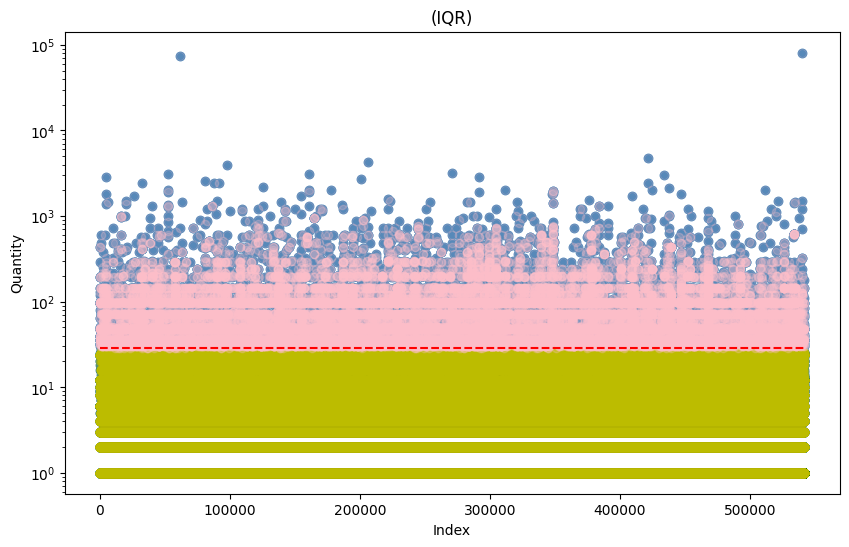

In [285]:
plt.figure(figsize=(10,6))
plt.scatter(df.index,df["Quantity"])
plt.hlines(upperbond,df.index[0],df.index[-1],linestyles="--",color="r")
plt.hlines(lowerbond,df.index[0],df.index[-1],linestyles="--",color="r")


# plt.ylim((-100,500))

filters=(df["Quantity"]<lowerbond)|(df["Quantity"]>upperbond)
outlier=df[filters]
cleaned=df[~filters]
plt.scatter(cleaned.index,cleaned["Quantity"],color="y",alpha=0.25)
plt.scatter(outlier.index,outlier["Quantity"],color="pink",alpha=0.25)

plt.yscale('log')

plt.title("(IQR)")
plt.xlabel("Index")
plt.ylabel("Quantity")

plt.show()

<div dir="rtl">

5درصد مشتریان ما بالای "upperbond"خرید می کنند ولی حذف کردن انها ریسک است چرا که به نظر می رسد شاید انها مشتریانی باشند که عمده خرید کرده اند.

In [286]:
len(df[df['Quantity'] > 28.5]) / len(df) * 100

5.132018128090885

<div dir="rtl">

2 مقدار داریم که فاصله آنها از بقیه بسیار زیاد است و طبق بررسی ها آن دو مشتری هیچ وقت در این حجم سفارش نداده اند پس به نظر می رسد که داده پرت باشند و حذف آنها کار درستی است.

In [287]:
df.sort_values(by="Quantity",ascending=False).head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,2011-10-27 12:26:00,0.21,12901.0,United Kingdom
206121,554868,22197,SMALL POPCORN HOLDER,4300,2011-05-27 10:52:00,0.72,13135.0,United Kingdom
97432,544612,22053,EMPIRE DESIGN ROSETTE,3906,2011-02-22 10:43:00,0.82,18087.0,United Kingdom


In [288]:
df[df["CustomerID"]==16446.0]


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
194354,553573,22980,PANTRY SCRUBBING BRUSH,1,2011-05-18 09:52:00,1.65,16446.0,United Kingdom
194355,553573,22982,PANTRY PASTRY BRUSH,1,2011-05-18 09:52:00,1.25,16446.0,United Kingdom
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom


In [289]:
df[df["CustomerID"]==12346.0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom


<div dir="rtl">

**بررسی "OUTLIER" با روش "Z-SCORE":**

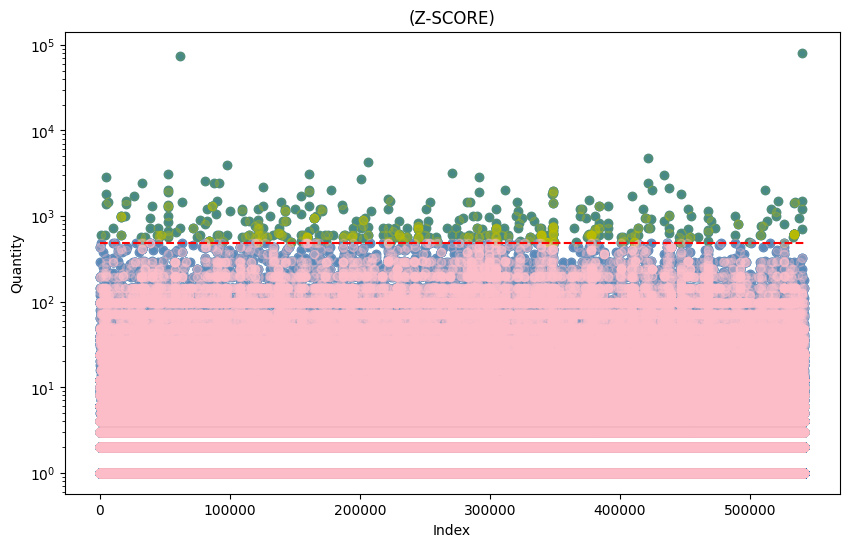

In [290]:
mean = df["Quantity"].mean()
std = df["Quantity"].std()
upperbond = mean + std * 3
lowerbond = mean - std * 3

plt.figure(figsize=(10,6))
plt.scatter(df.index,df["Quantity"])
plt.hlines(upperbond,df.index[0],df.index[-1],linestyles="--",color="r")
plt.hlines(lowerbond,df.index[0],df.index[-1],linestyles="--",color="r")

filter = (df["Quantity"] > upperbond)|(df["Quantity"] < lowerbond)
outlier = df[filter]
cleaned = df[~filter]
plt.scatter(outlier.index,outlier["Quantity"], alpha = 0.25, color="y")
plt.scatter(cleaned.index, cleaned["Quantity"], alpha = 0.25, color="pink")

plt.yscale('log')

plt.title("(Z-SCORE)")
plt.xlabel("Index")
plt.ylabel("Quantity")

plt.show()


#plt.ylim((-500,5000))


ac<div dir="rtl">

0.08 درصد مشتریان ما در روش "Z-SCORE" بالای "upperbond"خرید می کنند ولی حذف کردن انها ریسک است چرا که به نظر می رسد شاید انها مشتریانی باشند که عمده خرید کرده اند. ولی همچنان 2 مقدار داریم که فاصله آنها از بقیه بسیار زیاد است که حذف آنها همچنان کار درستی است.

In [291]:
len(df[df["Quantity"]>upperbond])/len(df)*100

0.08420988164683907

<div dir="rtl">
چولگی به شدت مثبت نشان دهنده درست بودن حذف آن دو داده پرت هست.

In [292]:
df["Quantity"].skew()

np.float64(468.79039744535123)

<div dir="rtl">

حذف دو داده پرت

In [293]:
df=df[~df["InvoiceNo"].isin(["581483","541431"])]

<div dir="rtl">

با حذف آن دو داده چولگی به شدت کاهش پیدا کرد.

In [294]:
df["Quantity"].skew()

np.float64(33.38734550225398)

<div dir="rtl">

داده‌ها دارای توزیع نامتقارن راست‌چوله هستند.

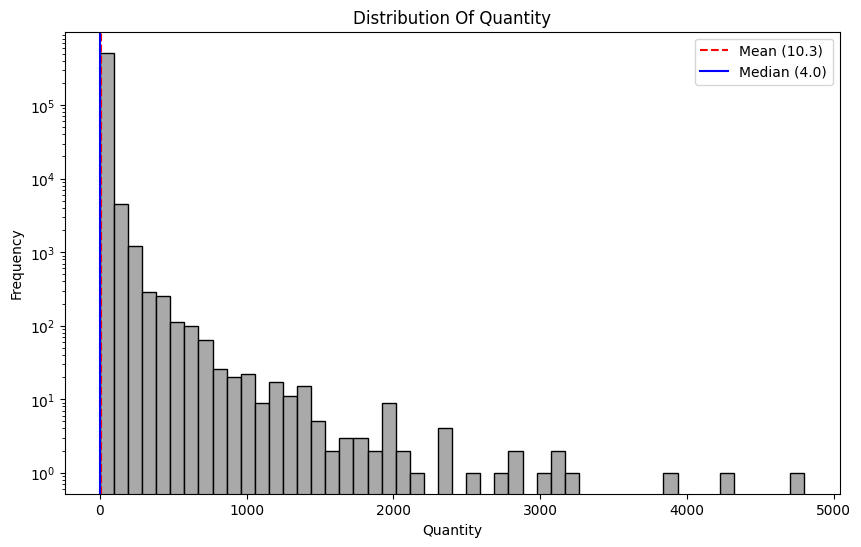

In [295]:
plt.figure(figsize=(10,6))
plt.hist(df["Quantity"],bins=50, color="darkgray",edgecolor="black")

mean = df["Quantity"].mean()
median = df["Quantity"].median()

plt.axvline(mean, color='red', linestyle='--',  label=f'Mean ({mean:.1f})')
plt.axvline(median, color='blue', linestyle='-', label=f'Median ({median:.1f})')

plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.title("Distribution Of Quantity")
plt.yscale('log')
plt.legend()
plt.show()

<div dir="rtl">

### ۵.۲ UnitPrice

In [296]:
df["UnitPrice"].describe()

,UnitPrice
count,522502.000000
mean,3.273900
std,4.393156
min,0.040000
25%,1.250000
50%,2.080000
75%,4.130000
max,649.500000


In [297]:
print("Range:", df["UnitPrice"].min(), df["UnitPrice"].max())

Range: 0.04 649.5


<div dir="rtl">

**بررسی "OUTLIER" با روش "IQR":**

In [298]:
Q1= np.quantile(df["UnitPrice"],0.25)
Q2= np.quantile(df["UnitPrice"],0.5)
Q3= np.quantile(df["UnitPrice"],0.75)
Q1, Q2, Q3

(np.float64(1.25), np.float64(2.08), np.float64(4.13))

In [299]:
IQR= Q3 - Q1
upperbond= Q3 + IQR * 1.5
lowerbond= Q1 - IQR * 1.5
upperbond, lowerbond

(np.float64(8.45), np.float64(-3.0700000000000003))

/tmp/ipykernel_3613/85869459.py:21: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


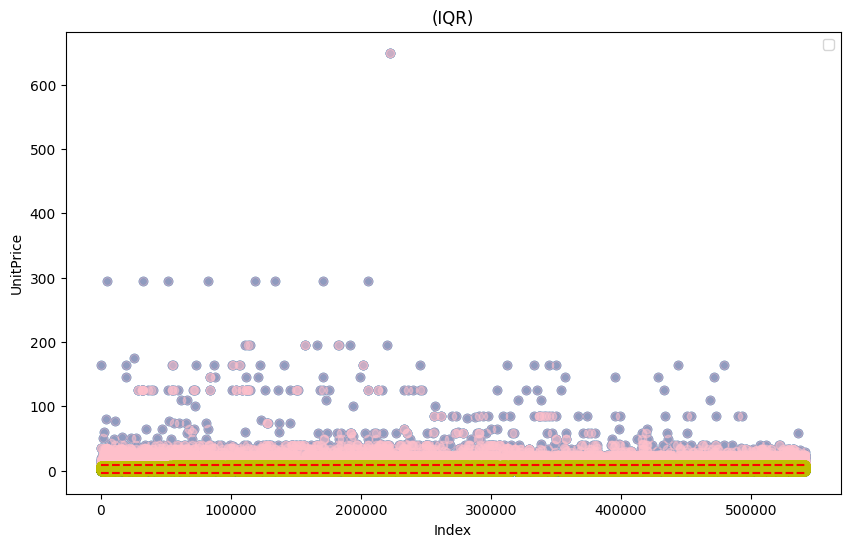

In [300]:
plt.figure(figsize= (10,6))

plt.scatter(df.index,df["UnitPrice"])
plt.hlines(upperbond,df.index[0], df.index[-1], linestyles="--", color= "r")
plt.hlines(lowerbond,df.index[0], df.index[-1], linestyles="--", color= "r")


filter= (df["UnitPrice"] > upperbond) | (df["UnitPrice"] < lowerbond)
outlier= df[filter]
cleaned= df[~filter]
plt.scatter(outlier.index, outlier["UnitPrice"], alpha= 0.50, color= "pink")
plt.scatter(cleaned.index, cleaned["UnitPrice"], alpha= 0.50, color= "y")



# plt.yscale('log')

plt.title("(IQR)")
plt.xlabel("Index")
plt.ylabel("UnitPrice")
plt.legend()
plt.show()


<div dir="rtl">

6.8 درصد قیمت های ما بالای "upperbond"هستند ولی حذف کردن انها ریسک است چرا که به نظر می رسد شاید انها کالای لوکس باشند.

In [301]:

len(df[df["UnitPrice"] > upperbond]) / len(df) * 100

6.840930752418172

<div dir="rtl">
داده‌های بالای مرز آماری (
 در IQR یا مرز Z-Score) مربوط به کالاهای لوکس و واقعی کاتالوگ (مانند ست پیک‌نیک و کابینت) هستند و حذف آن‌ها منطقی نیست.

In [302]:
df.sort_values(by= "UnitPrice", ascending=False).head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
222682,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,2011-06-10 15:33:00,649.5,15098.0,United Kingdom
222680,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,2011-06-10 15:28:00,649.5,15098.0,United Kingdom
133994,547814,22656,VINTAGE BLUE KITCHEN CABINET,1,2011-03-25 14:19:00,295.0,13452.0,United Kingdom
51636,540647,22655,VINTAGE RED KITCHEN CABINET,1,2011-01-10 14:57:00,295.0,17406.0,United Kingdom
118769,546480,22656,VINTAGE BLUE KITCHEN CABINET,1,2011-03-14 11:38:00,295.0,13452.0,United Kingdom


<div dir="rtl">

**بررسی "OUTLIER" با روش "Z-SCORE":**

/tmp/ipykernel_3613/1354874925.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


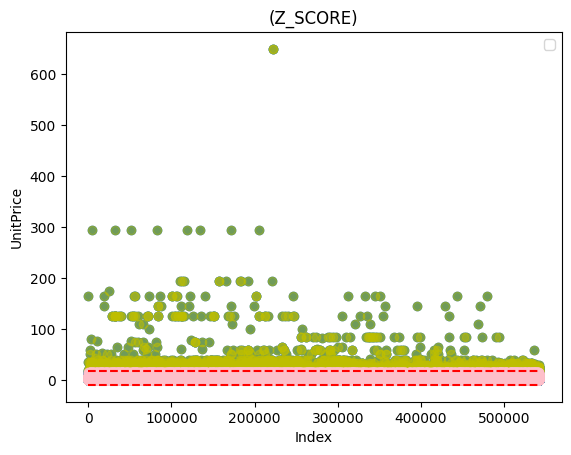

In [303]:
mean= df["UnitPrice"].mean()
std= df["UnitPrice"].std()

upperbond= mean + std * 3
lowerbond= mean - std * 3


plt.scatter(df.index, df["UnitPrice"])

plt.hlines(upperbond, df.index[0], df.index[-1], linestyles= "--", color= "r")
plt.hlines(lowerbond, df.index[0], df.index[-1], linestyles= "--", color= "r")

filter= (df['UnitPrice'] > upperbond) | (df['UnitPrice'] < lowerbond)
outlier= df[filter]
cleaned= df[~filter]

plt.scatter(outlier.index, outlier["UnitPrice"], alpha= 0.5, color= "y")
plt.scatter(cleaned.index, cleaned["UnitPrice"], alpha= 0.5, color= "pink")

plt.title("(Z_SCORE)")
plt.xlabel("Index")
plt.ylabel("UnitPrice")

plt.show()


ac<div dir="rtl">

1.2 درصد قیمت های ما در روش "Z-SCORE" بالای "upperbond"هستند.

In [304]:
len(df[df["UnitPrice"] > upperbond])/len(df)

0.012294689781091748

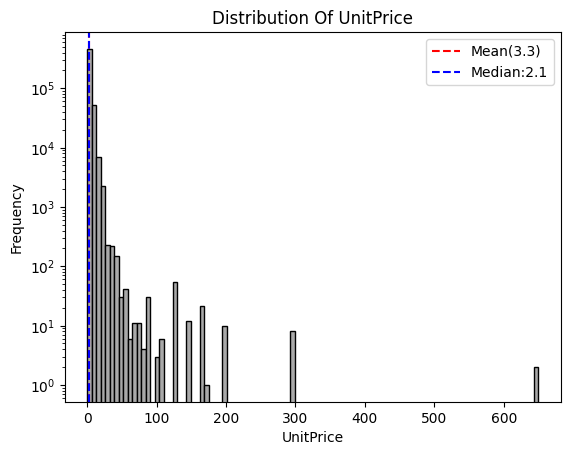

In [305]:

plt.hist(df['UnitPrice'], bins= 100, color= "darkgray", edgecolor= "black")

mean= df['UnitPrice'].mean()
median= df['UnitPrice'].median()

plt.axvline(mean, color="r", linestyle="--", label= f'Mean({mean:.1f})')
plt.axvline(median, color="b", linestyle="--", label= f"Median:{median:.1f}")


plt.xlabel("UnitPrice")
plt.ylabel("Frequency")
plt.title("Distribution Of UnitPrice")
plt.yscale('log')
plt.legend()
plt.show()



<div dir="rtl">

## ۶. استخراج ویژگی

</div>

<div dir="rtl">

ساخت ویژگی درآمد کل (TotalPrice):
اول از همه باید ستون TotalPrice = Quantity * UnitPrice را بسازیم تا درآمد حاصل از هر ردیف فاکتور را داشته باشیم.

In [306]:
df['TotalPrice'] = df['Quantity'] * df['UnitPrice']

<div dir="rtl">

## ۷. تحلیل اکتشافی (EDA)


</div>


<div dir="rtl">

### ۷.۱ فروش به تفکیک کشور


In [307]:
country_summary = (
    df.groupby('Country')
      .agg(
          TransactionRows=('InvoiceNo', 'size'),
          UniqueCustomers=('CustomerID', 'nunique'),
          TotalQuantity=('Quantity', 'sum'),
          TotalRevenue=('TotalPrice', 'sum')
      )
      .sort_values('TotalRevenue', ascending=False)
)

country_summary.head(10)


,TransactionRows,UniqueCustomers,TotalQuantity,TotalRevenue
Country,,,,
United Kingdom,478836,3916,4483797,8478392.02
Netherlands,2322,9,200258,283889.34
EIRE,7768,4,146896,270850.86
Germany,8643,94,118032,205381.15
France,8085,88,111226,184493.00
Australia,1180,9,83890,138103.81
Spain,2417,30,27724,55706.56
Switzerland,1927,22,30515,53065.60
Japan,321,8,26016,37416.37


<div dir="rtl">

همان‌طور که می‌بینید، United Kingdom با فاصله بسیار زیادی (بیش از ۸ میلیون درآمد) بالاتر از سایر کشورها قرار دارد.

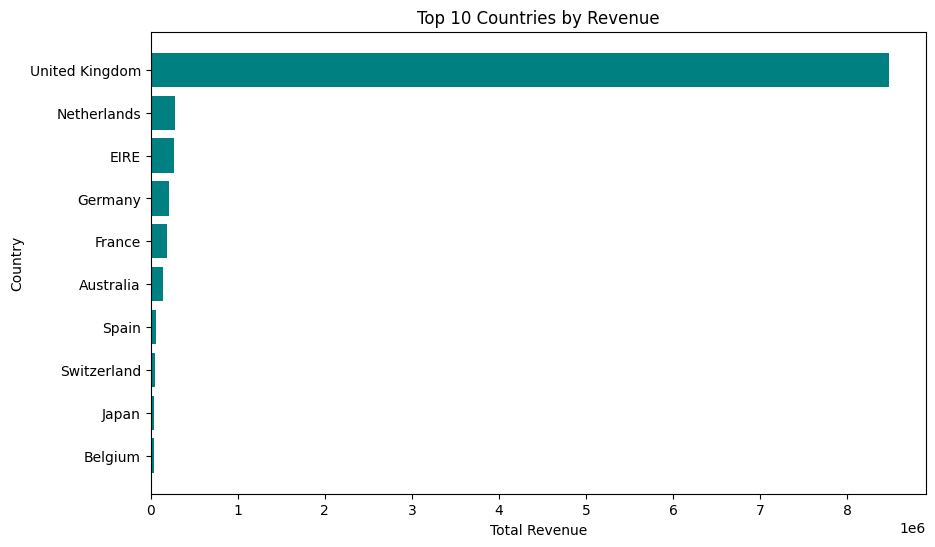

In [308]:
top10_revenue = country_summary.head(10).sort_values("TotalRevenue")

plt.figure(figsize=(10, 6))

plt.barh(top10_revenue.index, top10_revenue["TotalRevenue"], color="teal")

plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.title("Top 10 Countries by Revenue")

plt.show()


<div dir="rtl">

"United Kingdom" تقریباً کل فروش را در دست دارد، بنابراین برای دیدن سایر
کشورها، آن را از نمودار کنار گذاشتیم.هلند،  (EIRE)، آلمان، فرانسه و استرالیا مهم‌ترین بازارهای خارجی‌ هستند
</div>


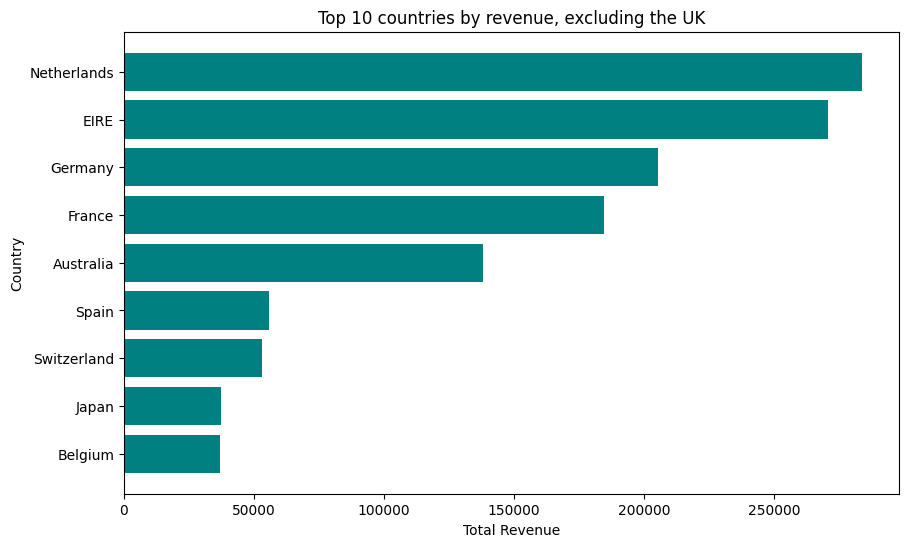

In [309]:
top_others = top10_revenue.drop('United Kingdom').head(10)

plt.figure(figsize=(10, 6))

plt.barh(top_others.index, top_others["TotalRevenue"], color="teal")

plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.title("Top 10 countries by revenue, excluding the UK")

plt.show()

<div dir="rtl">

### ۷.۲ محصولات پرفروش

<div dir="rtl">

محصول پرفروش بر اساس تعداد:

 اسباب‌بازی‌های کاغذی (`WORLD WAR 2 GLIDERS ASSTD DESIGNS`) و ساک‌های خرید (`JUMBO BAG`) بیشترین (تعداد) را در بین مشتریان به خود اختصاص داده‌اند.


</div>



In [310]:
top_quantity_products = (
    df.groupby(["StockCode", "Description"])["Quantity"]
      .sum()
      .reset_index()
      .sort_values(by="Quantity", ascending=False)
      .head(10)
)

print("--- Top 10 Products by Quantity ---")
top_quantity_products



--- Top 10 Products by Quantity ---


,StockCode,Description,Quantity
3088,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951
3519,85099B,JUMBO BAG RED RETROSPOT,48371
3536,85123A,WHITE HANGING HEART T-LIGHT HOLDER,37872
1124,22197,POPCORN HOLDER,36749
443,21212,PACK OF 72 RETROSPOT CAKE CASES,36396
3350,84879,ASSORTED COLOUR BIRD ORNAMENT,36362
2024,23084,RABBIT NIGHT LIGHT,30739
1400,22492,MINI PAINT SET VINTAGE,26633
1523,22616,PACK OF 12 LONDON TISSUES,26119
941,21977,PACK OF 60 PINK PAISLEY CAKE CASES,24820


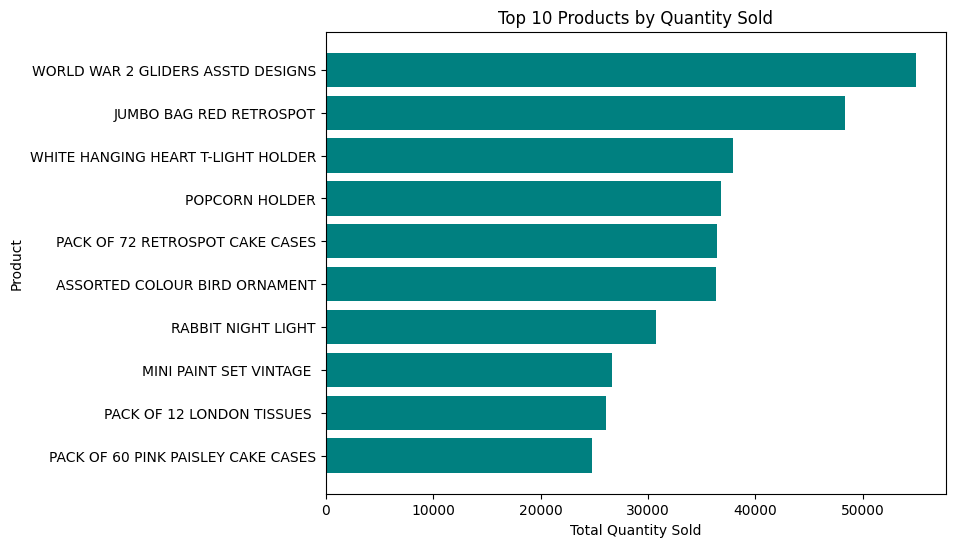

In [311]:

top_quantity_products = top_quantity_products.iloc[::-1]

plt.figure(figsize=(8, 6))
plt.barh(
    top_quantity_products["Description"],
    top_quantity_products["Quantity"],
    color="teal"
)
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.title("Top 10 Products by Quantity Sold")

plt.show()


<div dir="rtl">

محصول پرفروش بر اساس درآمد کل:

محصول REGENCY CAKESTAND 3 TIER با فاصله‌ای زیاد نسبت به بقیه، بیشترین درآمد را برای فروشگاه ایجاد کرده است.اقلام دکوراتیف، جا شمعی‌ها و ریسه‌های تزئینی (WHITE HANGING HEART T-LIGHT HOLDER و PARTY BUNTING) در رتبه‌های بعدی قرار دارند.


In [312]:
top_revenue_products = (
    df.groupby(["StockCode","Description"])["TotalPrice"]
      .sum()
      .reset_index()
      .sort_values(by="TotalPrice", ascending=False)
      .head(10)
)

print("--- Top 10 Products by Revenue ---")
top_revenue_products

--- Top 10 Products by Revenue ---


,StockCode,Description,TotalPrice
1335,22423,REGENCY CAKESTAND 3 TIER,174156.54
3536,85123A,WHITE HANGING HEART T-LIGHT HOLDER,106236.72
2864,47566,PARTY BUNTING,99445.23
3519,85099B,JUMBO BAG RED RETROSPOT,94159.81
2024,23084,RABBIT NIGHT LIGHT,66870.03
1017,22086,PAPER CHAIN KIT 50'S CHRISTMAS,64875.59
3350,84879,ASSORTED COLOUR BIRD ORNAMENT,58927.62
3028,79321,CHILLI LIGHTS,54096.36
2280,23298,SPOTTY BUNTING,42513.48
1302,22386,JUMBO BAG PINK POLKADOT,42401.01


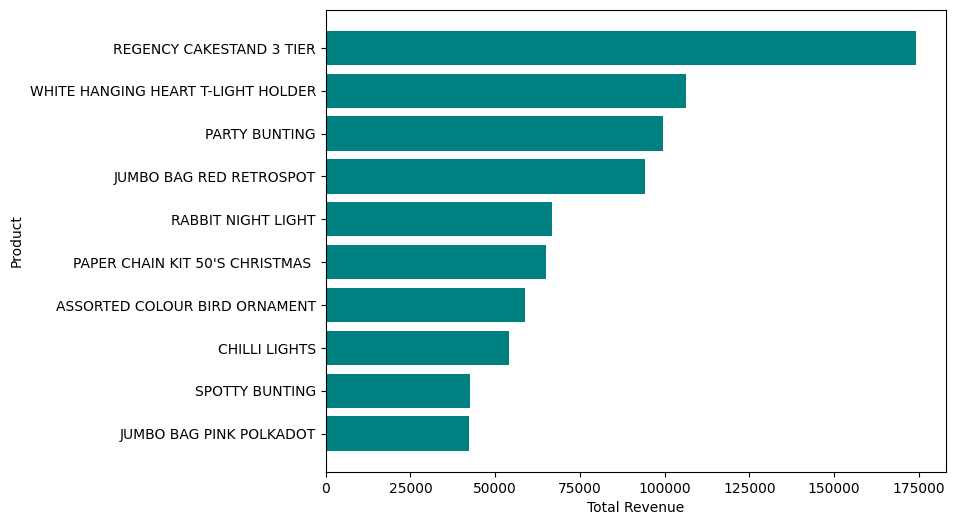

In [313]:
top_revenue_products = top_revenue_products.iloc[::-1]

plt.figure(figsize=(8, 6))
plt.barh(
    top_revenue_products["Description"],
    top_revenue_products["TotalPrice"],
    color="teal"
)
plt.xlabel("Total Revenue")
plt.ylabel("Product")

plt.show()

<div dir="rtl">


مقایسه دو نمودار با هم  نشان می‌دهد که محصولات پرفروش از نظر تعداد، الزاماً پردرآمدترین‌ها نیستند .

<div dir="rtl">

### ۷.۳ الگوی ساعتی و روزهای هفته

</div>

In [314]:
df["YearMonth"]= df["InvoiceDate"].dt.to_period("M")
df["Month"]= df["InvoiceDate"].dt.month
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

df[['InvoiceDate', 'YearMonth', 'DayOfWeek', 'Hour', 'TotalPrice']].head()

,InvoiceDate,YearMonth,DayOfWeek,Hour,TotalPrice
0,2010-12-01 08:26:00,2010-12,Wednesday,8,15.30
1,2010-12-01 08:26:00,2010-12,Wednesday,8,20.34
2,2010-12-01 08:26:00,2010-12,Wednesday,8,22.00
3,2010-12-01 08:26:00,2010-12,Wednesday,8,20.34
4,2010-12-01 08:26:00,2010-12,Wednesday,8,20.34


<div dir="rtl">

#### فروش ماهانه


In [315]:
monthly_sales= (df.groupby("YearMonth").agg(
    Revenue=("TotalPrice","sum"),
     Orders=("InvoiceNo", "nunique")
).reset_index()
)

<div dir="rtl">

درآمد در نوامبر ۲۰۱۱ به اوج می‌رسد: حدود ۱٫۴۵ میلیون؛ همان ماهی که تعداد سفارش‌ها نیز بیشترین مقدار را دارد.
پس از اوج نوامبر، هر دو شاخص در دسامبر پایین می‌آیند؛ اما **دسامبر ۲۰۱۱ ناقص است** (داده فقط تا ۹ دسامبر است) و این افت واقعی نیست و نباید با ماه‌های کامل مقایسه شود.

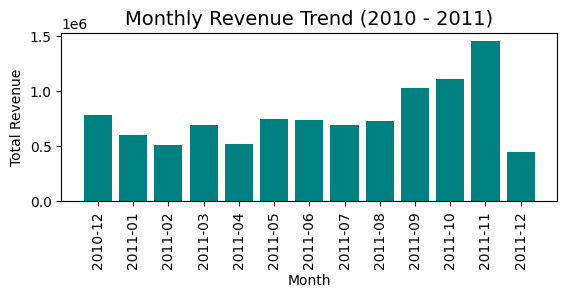

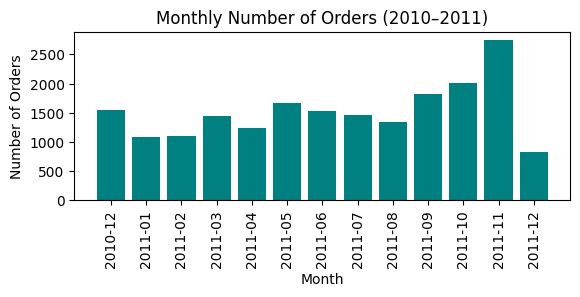

In [316]:
plt.subplot(211)

plt.bar(monthly_sales["YearMonth"].astype(str), monthly_sales["Revenue"], color="teal")
plt.title("Monthly Revenue Trend (2010 - 2011)", fontsize=14)
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.show()

plt.subplot(212)
plt.bar(monthly_sales["YearMonth"].astype(str), monthly_sales["Orders"], color="teal")
plt.title('Monthly Number of Orders (2010–2011)')
plt.xlabel('Month')
plt.ylabel('Number of Orders')
plt.xticks(rotation=90)


plt.show()

<div dir="rtl">

#### رفتار خرید بر اساس روزهای هفته

<div dir="rtl">

 الگوی درآمد و تعداد سفارش کاملاً با هم همخوانی دارند؛ یعنی پنج‌شنبه‌ها هم از نظر تعداد فاکتور و هم از نظر حجم درآمد در بالاترین سطح قرار دارند و یکشنبه‌ها کمترین میزان خرید را به خود اختصاص داده‌اند. به نظر می رسد، روز شنبه در این فروشگاه تعطیل یا بدون تراکنش بوده است.

In [317]:
weekly_sales = (df.groupby("DayOfWeek").agg(
    Revenue=("TotalPrice","sum"),
     Orders=("InvoiceNo", "nunique")
).reset_index()
)

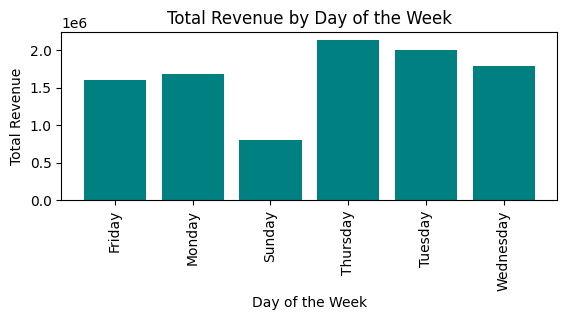

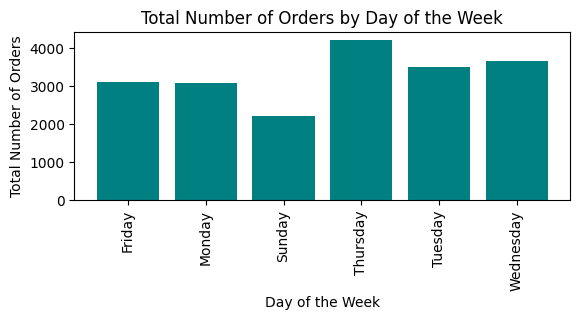

In [318]:
plt.subplot(211)
plt.bar(weekly_sales["DayOfWeek"].astype(str), weekly_sales["Revenue"], color="teal")
plt.title('Total Revenue by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Revenue')
plt.xticks(rotation=90)
plt.show()

plt.subplot(212)
plt.bar(weekly_sales["DayOfWeek"].astype(str), weekly_sales["Orders"], color="teal")
plt.title('Total Number of Orders by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Total Number of Orders')
plt.xticks(rotation=90)
plt.show()

<div dir="rtl">

#### رفتار خرید بر اساس ساعات

<div dir="rtl">

بیشترین حجم درآمد و تعداد سفارش در بازه زمانی ساعت ۱۰ صبح تا ۳ بعدازظهر (ساعت ۱۰ تا ۱۵) ثبت شده است که قله‌ی آن در ساعت ۱۲ (ظهر) قرار دارد.

In [319]:
hourly_sales = (df.groupby("Hour").agg(
    Revenue=("TotalPrice","sum"),
     Orders=("InvoiceNo", "nunique")
).reset_index()
)

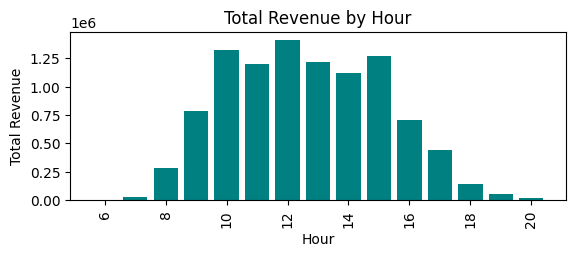

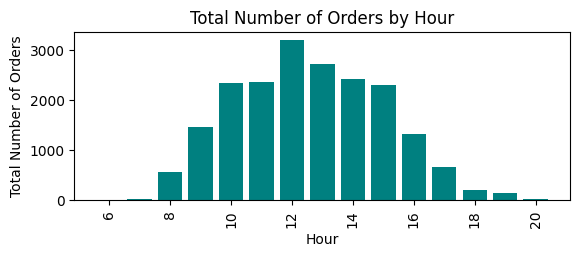

In [320]:
plt.subplot(211)
plt.bar(hourly_sales["Hour"], hourly_sales["Revenue"], color="teal")
plt.title('Total Revenue by Hour')
plt.xlabel('Hour')
plt.ylabel('Total Revenue')
plt.xticks(rotation=90)
plt.show()

plt.subplot(212)
plt.bar(hourly_sales["Hour"], hourly_sales["Orders"], color="teal")
plt.title('Total Number of Orders by Hour')
plt.xlabel('Hour')
plt.ylabel('Total Number of Orders')
plt.xticks(rotation=90)
plt.show()

<div dir="rtl">


## ۸. توزیع‌های احتمالی

<div dir="rtl">

### ۸.۱ توزیع نرمال (قیمت واحد)

قیمت واحد لگ‌نرمال است، یعنی خودش نرمال نیست ولی لگاریتمش نرمال است.

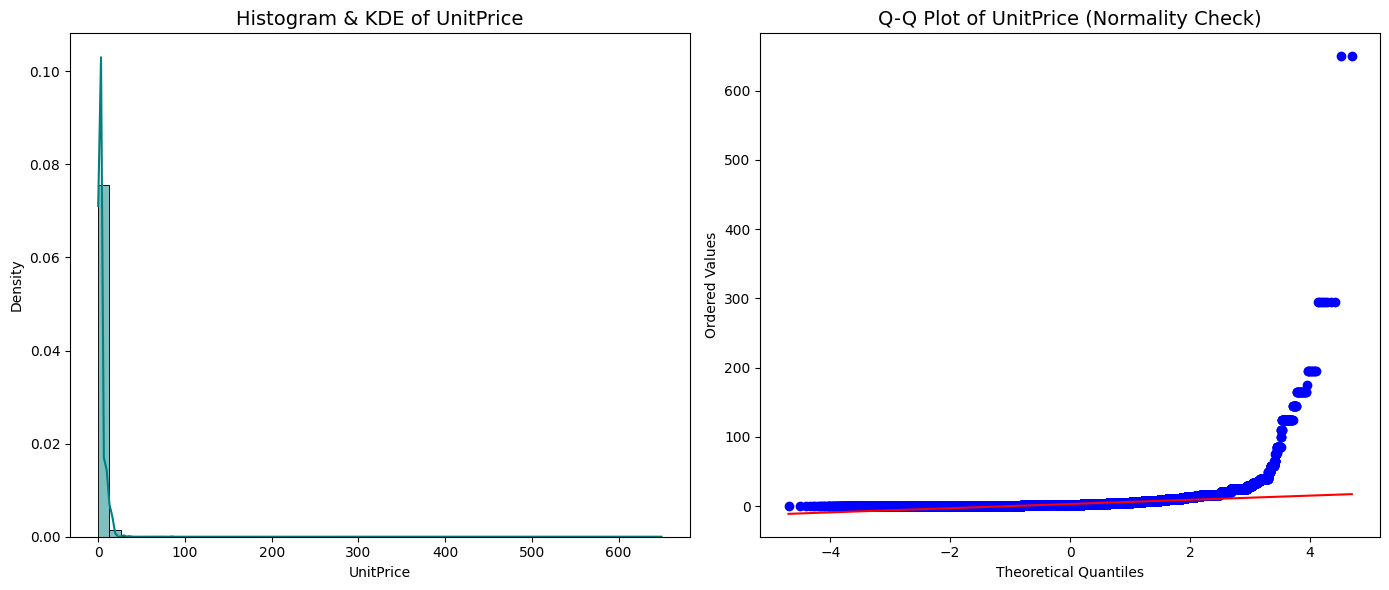

In [321]:
target_col = 'UnitPrice'

plt.figure(figsize=(14, 6))


plt.subplot(1, 2, 1)
sns.histplot(df[target_col], bins=50, color='teal', kde=True, stat='density')
plt.title(f'Histogram & KDE of {target_col}', fontsize=14)
plt.xlabel(target_col)
plt.ylabel('Density')



plt.subplot(1, 2, 2)
stats.probplot(df[target_col], dist="norm", plot=plt)
plt.title(f'Q-Q Plot of {target_col} (Normality Check)', fontsize=14)
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Ordered Values')

plt.tight_layout()
plt.show()


mu = 0.758   sigma = 0.929   skew = -0.05   kurt = -0.02


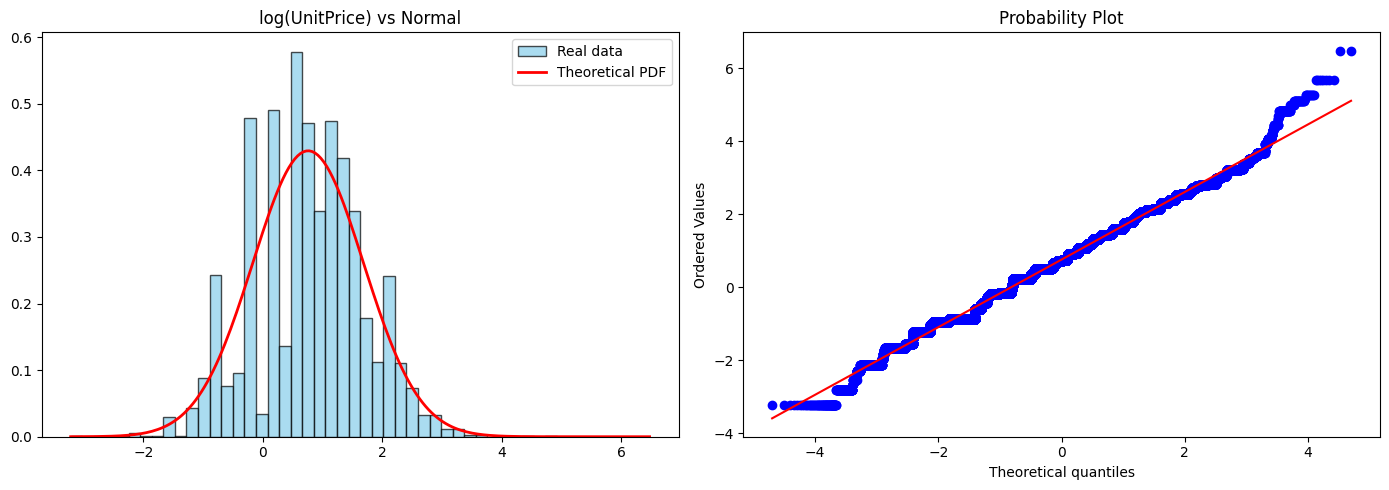

In [322]:
lp = np.log(df["UnitPrice"])
mu, sigma = lp.mean(), lp.std()
print(f"mu = {mu:.3f}   sigma = {sigma:.3f}   skew = {lp.skew():.2f}   kurt = {lp.kurt():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


axes[0].hist(lp, bins=50, density=True, alpha=0.7, color='skyblue', edgecolor='black', label='Real data')
x = np.linspace(lp.min(), lp.max(), 200)
axes[0].plot(x, stats.norm.pdf(x, mu, sigma), 'r-', lw=2, label='Theoretical PDF')
axes[0].set_title('log(UnitPrice) vs Normal')
axes[0].legend()

# Q-Q plot
stats.probplot(lp, dist="norm", plot=axes[1])
plt.tight_layout()
plt.show()

In [323]:
inv = (df.groupby("InvoiceNo")
         .agg(InvoiceValue=("TotalPrice", "sum"),
              Items=("Quantity", "sum"),
              Lines=("StockCode", "count"),
              InvoiceDate=("InvoiceDate", "first"),
              Country=("Country", "first"),
              DayOfWeek=("DayOfWeek", "first"),
              Hour=("Hour", "first"))
         .reset_index())

inv["Group"] = np.where(inv["Country"] == "United Kingdom", "UK", "Other")
inv["Date"] = inv["InvoiceDate"].dt.date
inv = inv.sort_values("InvoiceDate")


<div dir="rtl">

### ۸.۲ توزیع نمایی (فاصله‌ی بین فاکتورها)

**سؤال:** فاصله‌ی زمانی بین دو فاکتور پشت‌سرهم در یک روز چه توزیعی دارد؟

**روش:** فاکتورها را بر اساس زمان مرتب کردیم. فقط ساعت 10 تا 15 را نگه داشتیم (پرترافیک‌ترین بازه) و فاصله‌ی هر فاکتور تا فاکتور قبلی **در همان روز** را به دقیقه حساب کردیم. تحلیل را در سطح **فاکتور** انجام دادیم، نه ردیف کالا؛ چون ردیف‌های یک فاکتور زمان یکسان دارند و فاصله‌ی صفر می‌سازند.

**نتیجه:**
- 12,759 فاصله با میانگین **6.7 دقیقه** به دست آمد.
- چندک‌های مشاهده‌شده (10، 25، 50، 75، 90 درصد) برابر 1، 2، 4، 9، 16 دقیقه است و چندک‌های توزیع نمایی با همان میانگین 0.7، 1.9، 4.6، 9.3، 15.4 است. این دو بسیار به هم نزدیک‌اند.
- بنابراین فاصله‌ی بین فاکتورها **تقریباً نمایی** است؛ یعنی فاکتورها تقریباً به‌صورت تصادفی و مستقل از هم می‌رسند.


</div>

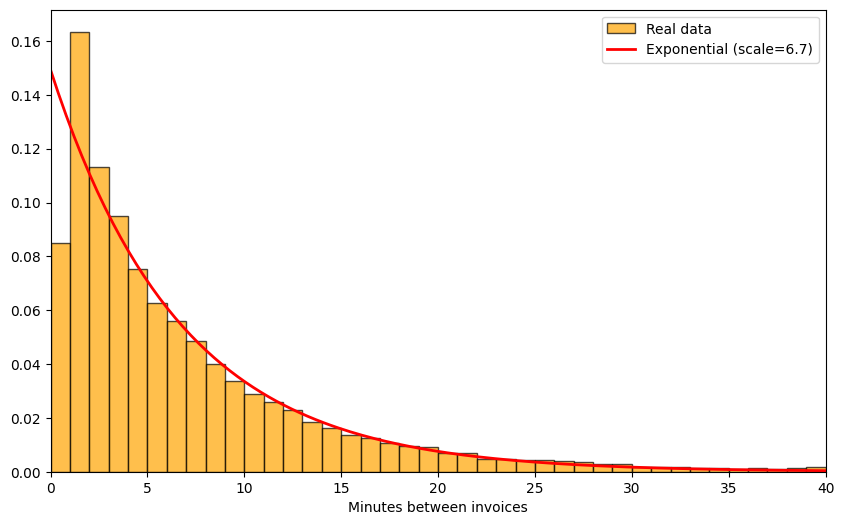

n: 12759 | mean: 6.7 | std: 7.814475141654895
observed quantiles: [1.0, 2.0, 4.0, 9.0, 16.0]
theory quantiles:   [0.7, 1.9, 4.6, 9.3, 15.4]


In [324]:
busy = inv[inv["Hour"].between(10, 14)].copy()
busy["Gap"] = busy.groupby("Date")["InvoiceDate"].diff().dt.total_seconds() / 60
gaps = busy["Gap"].dropna()
scale = gaps.mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(gaps, bins=np.arange(0, 41, 1), density=True, alpha=0.7, color='orange', edgecolor='black', label='Real data')
x = np.linspace(0, 40, 200)
ax.plot(x, stats.expon.pdf(x, scale=scale), 'r-', lw=2, label=f'Exponential (scale={scale:.1f})')
ax.set_xlim(0, 40)
ax.set_xlabel('Minutes between invoices')
ax.legend()
plt.show()

print("n:", len(gaps), "| mean:", gaps.mean().round(2), "| std:", gaps.std())
q = [0.1, 0.25, 0.5, 0.75, 0.9]
print("observed quantiles:", gaps.quantile(q).round(1).tolist())
print("theory quantiles:  ", stats.expon.ppf(q, scale=scale).round(1).tolist())

<div dir="rtl">

### ۸.۳ توزیع پواسون (تعداد فاکتور در ساعت ۱۲)

 تعداد فاکتورها در ساعت ۱۲ ظهر هر روز چه توزیعی دارد؟ پواسون نیاز دارد که نرخ ثابت باشد، پس یک بازه‌ی همگن انتخاب می‌کنیم: روزهای سه‌شنبه تا پنج‌شنبه، از مارس تا اوت ۲۰۱۱.

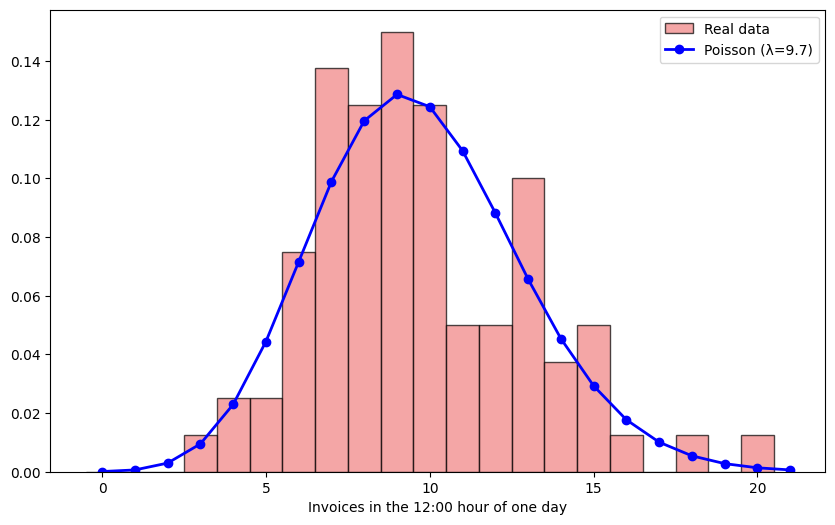

days: 80 | mean: 9.68 | var: 10.753797468354435


In [325]:
slot = inv[(inv["InvoiceDate"] >= "2011-03-01") & (inv["InvoiceDate"] < "2011-09-01")
           & (inv["Hour"] == 12)
           & (inv["DayOfWeek"].isin(["Tuesday", "Wednesday", "Thursday"]))]
counts = slot.groupby("Date").size()          # تعداد فاکتور هر روز در ساعت ۱۲
lam = counts.mean()

fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(counts, bins=np.arange(0, counts.max() + 2) - 0.5, density=True,
        alpha=0.7, color='lightcoral', edgecolor='black', label='Real data')
k = np.arange(0, counts.max() + 2)
ax.plot(k, stats.poisson.pmf(k, lam), 'bo-', lw=2, label=f'Poisson (λ={lam:.1f})')
ax.set_xlabel('Invoices in the 12:00 hour of one day')
ax.legend()
plt.show()

print("days:", len(counts), "| mean:", counts.mean().round(2), "| var:", counts.var())

<div dir="rtl">

## ۹. آزمون‌های آماری

### ۹.۰ مفاهیم پایه

- **فرضیه‌ی صفر (H₀):** فرضیه‌ای که می‌خواهیم رد کنیم (مثلاً «بین دو گروه تفاوتی نیست»).
- **فرضیه‌ی جایگزین (H₁):** فرضیه‌ای که در صورت رد H₀ می‌پذیریم.
- **سطح معناداری (α):** احتمال رد کردن H₀ در حالی که درست است (خطای نوع اول). ما **α = 0.05** را به کار می‌بریم.
- **p-value:** اگر H₀ درست باشد، با چه احتمالی نتیجه‌ای حداقل به این اندازه افراطی می‌دیدیم؟
  - اگر `p-value < α` ← H₀ را رد می‌کنیم.
  - اگر `p-value ≥ α` ← H₀ را رد نمی‌کنیم.
- **اندازه‌ی اثر (Effect Size):** p-value فقط می‌گوید تفاوت **وجود دارد**، نه اینکه **چقدر بزرگ** است.

> **نکته‌ی مهم:** داده‌ی ما هزاران تا صدها هزار ردیف دارد. با نمونه‌ی خیلی بزرگ، **حتی تفاوت‌های ناچیز هم p-value بسیار کوچک می‌دهند.** پس کنار هر p-value یک اندازه‌ی اثر هم گزارش می‌کنیم و فقط به «معنادار شد» بسنده نمی‌کنیم.

### کدام آزمون‌ها را انجام می‌دهیم؟

| آزمون | سؤال روی داده‌ی فروش |
|-------|-----------------------|
| آزمون‌های نرمال بودن (جارک-برا و KS) | آیا قیمت و ارزش فاکتور نرمال‌اند؟ فاصله‌ی بین فاکتورها نمایی است؟ |
| t-test مستقل | ارزش فاکتور مشتریان بریتانیایی در برابر سایر کشورها |
| Mann-Whitney U | همان سؤال، بدون فرض نرمال بودن |
| A/B Testing | ارزش فاکتورهای قبل از ظهر در برابر بعدازظهر |
| ANOVA | ارزش فاکتور بین روزهای هفته |
| کای‌دو | آیا سهم مشتریان خارجی در روزهای هفته و فصل‌ها فرق دارد؟ |

**آزمون‌هایی که انجام ندادیم و دلیلش:** t یک‌نمونه‌ای و Z-test به یک مقدار مرجع یا انحراف معیار معلوم نیاز دارند که در این داده مرجع طبیعی ندارد. t زوجی و Wilcoxon به **داده‌ی زوجی** نیاز دارند (یک واحد که دو بار اندازه‌گیری شود)، ولی فاکتورهای ما مستقل از هم‌اند.

**واحد تحلیل:** همه‌ی آزمون‌ها روی جدول **فاکتور** (`inv`) انجام می‌شوند، نه ردیف کالا؛ چون چند ردیف از یک فاکتور مستقل نیستند.

</div>

In [326]:
from scipy.stats import jarque_bera, kstest, ttest_ind, mannwhitneyu, f_oneway, chi2_contingency

alpha = 0.05
results = []


inv["LogValue"] = np.log(inv["InvoiceValue"])
inv[["InvoiceValue", "LogValue", "Group", "DayOfWeek", "Hour"]].head()

,InvoiceValue,LogValue,Group,DayOfWeek,Hour
0,139.12,4.935337,UK,Wednesday,8
1,22.20,3.100092,UK,Wednesday,8
2,278.73,5.630244,UK,Wednesday,8
3,70.05,4.249209,UK,Wednesday,8
4,17.85,2.882004,UK,Wednesday,8


<div dir="rtl">

### ۹.۱ آزمون‌های نرمال بودن (جارک-برا و کولموگروف-اسمیرنوف)

انتخاب بین آزمون‌های پارامتری (مثل t-test) و ناپارامتری به نرمال بودن داده بستگی دارد، پس اول آن را بررسی می‌کنیم.

#### آزمون جارک-برا (Jarque-Bera)
این آزمون **چولگی و کشیدگی** داده را با مقدار نرمال مقایسه می‌کند:

- H₀: داده نرمال است (چولگی = 0 و کشیدگی اضافه = 0)
- H₁: داده نرمال نیست
- آماره: `JB = n/6 × (چولگی² + کشیدگی²/4)` — به `n` در فرمول توجه کن.

</div>

In [327]:
candidates = {
    "Quantity": df["Quantity"],
    "UnitPrice": df["UnitPrice"],
    "TotalPrice": df["TotalPrice"],
    "InvoiceValue": inv["InvoiceValue"],
    "log(UnitPrice)": np.log(df["UnitPrice"]),
    "log(InvoiceValue)": inv["LogValue"],
}

rows = []
for name, x in candidates.items():
    jb = jarque_bera(x)
    rows.append({"variable": name, "n": len(x), "skew": x.skew(), "kurtosis": x.kurt(),
                 "JB": jb.statistic, "p-value": jb.pvalue})

jb_table = pd.DataFrame(rows).set_index("variable")
jb_table.map("{:.4g}".format)

,n,skew,kurtosis,JB,p-value
variable,,,,,
Quantity,5.225e+05,33.39,2212,1.067e+11,0
UnitPrice,5.225e+05,25.73,2345,1.198e+11,0
TotalPrice,5.225e+05,200.8,8.634e+04,1.623e+14,0
InvoiceValue,1.977e+04,17.1,521.3,2.247e+08,0
log(UnitPrice),5.225e+05,-0.04643,-0.022,198.2,8.988e-44
log(InvoiceValue),1.977e+04,-0.815,2.782,8558,0


<div dir="rtl">

متغیرهای خام قطعاً نرمال نیستند. اما **log(UnitPrice)** هم رد شده، با اینکه چولگی و کشیدگی‌اش تقریباً صفر است! دلیلش `n` در فرمول است. این را با آزمایش بعدی نشان می‌دهیم: از log قیمت نمونه‌هایی با اندازه‌های مختلف می‌گیریم و آزمون را تکرار می‌کنیم.

</div>

In [328]:
lp = np.log(df["UnitPrice"])

for n in [100, 1000, 5000, 50000, len(lp)]:
    s = lp.sample(n, random_state=42) if n < len(lp) else lp
    r = jarque_bera(s)
    print(f"n={n:>7}  skew={s.skew():+.3f}  kurt={s.kurt():+.3f}  JB={r.statistic:8.2f}  p={r.pvalue:.3g}")


np.random.seed(42)
z = np.random.normal(0, 1, 5000)
r = jarque_bera(z)
print(f"\nنمونه‌ی شبیه‌سازی‌شده‌ی نرمال:  JB={r.statistic:.2f}  p={r.pvalue:.3f}   → رد نمی‌شود")

n=    100  skew=+0.152  kurt=+0.145  JB=    0.40  p=0.819
n=   1000  skew=-0.107  kurt=-0.054  JB=    2.05  p=0.358
n=   5000  skew=-0.068  kurt=-0.113  JB=    6.57  p=0.0374
n=  50000  skew=-0.039  kurt=-0.044  JB=   16.78  p=0.000227
n= 522502  skew=-0.046  kurt=-0.022  JB=  198.24  p=8.99e-44

نمونه‌ی شبیه‌سازی‌شده‌ی نرمال:  JB=0.46  p=0.796   → رد نمی‌شود


<div dir="rtl">

#### آزمون کولموگروف-اسمیرنوف (KS)
این آزمون **کل شکل توزیع** را با یک توزیع نظری مقایسه می‌کند. آماره‌ی `D` بزرگ‌ترین فاصله‌ی بین دو نمودار تجمعی (داده و توزیع نظری) است.

- H₀: داده از آن توزیع آمده است.
- H₁: داده از آن توزیع نیامده است.

دو سؤال می‌پرسیم: آیا log قیمت **نرمال** است؟ آیا فاصله‌ی بین فاکتورها (`gaps` که در بخش نمایی ساختیم) **نمایی** است؟

</div>

In [329]:
mu, sigma = lp.mean(), lp.std()

ks_norm = kstest(lp, stats.norm(mu, sigma).cdf)
print(f"log(UnitPrice) در برابر نرمال:       D={ks_norm.statistic:.4f}   p={ks_norm.pvalue:.3g}")

ks_exp = kstest(gaps, stats.expon(scale=gaps.mean()).cdf)
print(f"فاصله‌ی فاکتورها در برابر نمایی:      D={ks_exp.statistic:.4f}   p={ks_exp.pvalue:.3g}")

# برای مقایسه: نمونه‌ی شبیه‌سازی‌شده‌ی نرمال (همان z بالا)
ks_sim = kstest(z, stats.norm(0, 1).cdf)
print(f"نمونه‌ی شبیه‌سازی‌شده در برابر نرمال: D={ks_sim.statistic:.4f}   p={ks_sim.pvalue:.3f}")

results.append({"test": "Jarque-Bera: log(UnitPrice) normal?", "statistic": jarque_bera(lp).statistic,
                "p-value": jarque_bera(lp).pvalue, "effect size": f"skew={lp.skew():.2f}, kurt={lp.kurt():.2f}"})
results.append({"test": "KS: gaps between invoices exponential?", "statistic": ks_exp.statistic,
                "p-value": ks_exp.pvalue, "effect size": f"D = {ks_exp.statistic:.3f}"})

log(UnitPrice) در برابر نرمال:       D=0.0689   p=0
فاصله‌ی فاکتورها در برابر نمایی:      D=0.1082   p=1.84e-130
نمونه‌ی شبیه‌سازی‌شده در برابر نرمال: D=0.0129   p=0.369


<div dir="rtl">

**تفسیر:**

- متغیرهای خام (`Quantity`، `UnitPrice`، `TotalPrice` و ارزش فاکتور) به‌شدت چوله‌اند (چولگی 17 تا 200) و جارک-برا نرمال بودنشان را قاطعانه رد می‌کند.
- **log(UnitPrice)** چولگی ‎−0.046 و کشیدگی ‎−0.022 دارد و از نظر شکل بسیار به نرمال نزدیک است، اما با 522 هزار ردیف، هر دو آزمون (JB با p ≈ 9×10⁻⁴⁴ و KS با p ≈ 0) آن را رد می‌کنند. در آزمایش نمونه‌گیری دیدیم چولگی و کشیدگی تقریباً ثابت می‌مانند ولی **p-value فقط با بزرگ شدن n از 0.82 (n=100) تا ‎۰ می‌رسد**. پس «رد شدن» اینجا به معنای «شکل خیلی متفاوت» نیست.
- **فاصله‌ی فاکتورها:** KS نمایی بودن را رد می‌کند (D = 0.108). هیستوگرام و چندک‌ها شباهت زیادی را نشان دادند، اما زمان‌ها تا دقیقه گرد شده‌اند (حدود 8٪ فاصله‌ها صفرند) و نرخ فروش در طول سال ثابت نیست.
- **ارزش فاکتور** حتی بعد از لگاریتم هم کمی چوله است (‎−0.82).

**تصمیم:** چون فرض نرمال بودن در سطح دقیق برقرار نیست، علاوه بر t-test از آزمون‌های **ناپارامتری** (Mann-Whitney) و **شبیه‌سازی** (A/B) هم استفاده می‌کنیم تا نتیجه به این فرض وابسته نباشد. اگر هر سه یک نتیجه بدهند، به آن اعتماد بیشتری داریم.

</div>

<div dir="rtl">

### ۹.۲ آزمون t مستقل: ارزش فاکتور در بریتانیا و سایر کشورها

دو گروه **مستقل** داریم: فاکتورهای مشتریان بریتانیا (`UK`) و بقیه‌ی کشورها (`Other`).

- H₀: میانگین ارزش فاکتور در دو گروه برابر است.
- H₁: میانگین ارزش فاکتور در دو گروه فرق دارد.

**نکته‌ی فنی:** با `equal_var=False` از **t-test ولچ** استفاده می‌کنیم که برابری واریانس‌ها را فرض نمی‌گیرد (انحراف معیار دو گروه خیلی فرق دارد). آزمون را یک بار روی مقدار **خام** و یک بار روی **لگاریتم** اجرا می‌کنیم، چون لگاریتم داده را به نرمال نزدیک‌تر می‌کند. اندازه‌ی اثر: **Cohen's d** (حدود 0.2 کوچک، 0.5 متوسط، 0.8 بزرگ).

</div>

UK:    n=17,899   median= 299.60   mean= 473.68   std= 1094.90
Other: n= 1,872   median= 385.28   mean= 813.45   std= 1759.52

t-test (خام):     t =   8.19   p = 4.55e-16
t-test (لگاریتم): t =  16.22   p = 3.8e-56

Cohen d = 0.38
میانگین هندسی: UK=246.7   Other=390.0   نسبت = 1.58


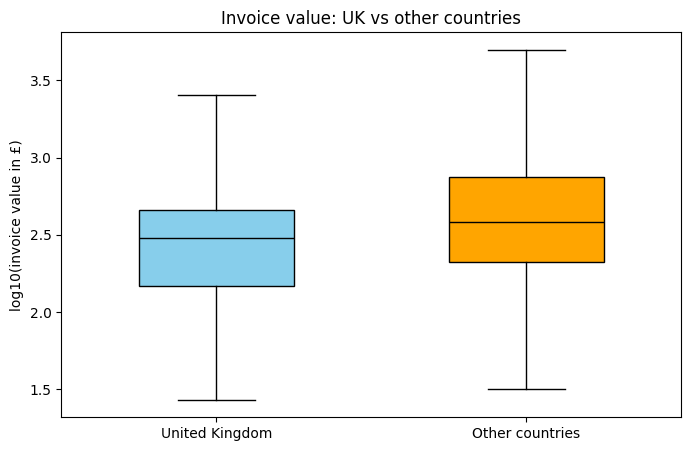

In [330]:
uk    = inv.loc[inv["Group"] == "UK", "InvoiceValue"]
other = inv.loc[inv["Group"] == "Other", "InvoiceValue"]

print(f"UK:    n={len(uk):>6,}   median={uk.median():7.2f}   mean={uk.mean():7.2f}   std={uk.std():8.2f}")
print(f"Other: n={len(other):>6,}   median={other.median():7.2f}   mean={other.mean():7.2f}   std={other.std():8.2f}")

# t-test روی داده‌ی خام
t_raw = ttest_ind(other, uk, equal_var=False)
print(f"\nt-test (خام):     t = {t_raw.statistic:6.2f}   p = {t_raw.pvalue:.3g}")

# t-test روی لگاریتم
log_uk, log_other = np.log(uk), np.log(other)
t_log = ttest_ind(log_other, log_uk, equal_var=False)
print(f"t-test (لگاریتم): t = {t_log.statistic:6.2f}   p = {t_log.pvalue:.3g}")

# اندازه‌ی اثر روی لگاریتم
pooled_sd = np.sqrt(((len(uk) - 1) * log_uk.var() + (len(other) - 1) * log_other.var()) / (len(uk) + len(other) - 2))
cohen_d = (log_other.mean() - log_uk.mean()) / pooled_sd
ratio = np.exp(log_other.mean() - log_uk.mean())      # نسبت میانگین‌های هندسی
print(f"\nCohen d = {cohen_d:.2f}")
print(f"میانگین هندسی: UK={np.exp(log_uk.mean()):.1f}   Other={np.exp(log_other.mean()):.1f}   نسبت = {ratio:.2f}")

results.append({"test": "Welch t-test: Other vs UK (log invoice value)", "statistic": t_log.statistic,
                "p-value": t_log.pvalue, "effect size": f"d = {cohen_d:.2f}"})

fig, ax = plt.subplots(figsize=(8, 5))
bp = ax.boxplot([np.log10(uk), np.log10(other)], patch_artist=True, showfliers=False, widths=0.5,
                medianprops=dict(color="black"))
ax.set_xticklabels(["United Kingdom", "Other countries"])
for patch, c in zip(bp["boxes"], ["skyblue", "orange"]):
    patch.set_facecolor(c)
ax.set_ylabel("log10(invoice value in £)")
ax.set_title("Invoice value: UK vs other countries")
plt.show()

<div dir="rtl">

**تفسیر:**

- **تصمیم:** در هر دو حالت (خام و لگاریتمی) p بسیار کمتر از 0.05 است (p ≈ 5×10⁻¹⁶ و p ≈ 4×10⁻⁵⁶)، پس **H₀ رد می‌شود**: ارزش فاکتور در دو گروه فرق دارد.
- **جهت:** فاکتورهای مشتریان خارجی **بزرگ‌ترند**. میانه‌ی آن‌ها حدود 385 پوند در برابر حدود 300 پوند در بریتانیا است. میانگین‌ها (813 در برابر 474 پوند) تفاوت را بیشتر نشان می‌دهند، چون چند فاکتور خیلی بزرگ میانگین را بالا می‌کشند.
- **اندازه‌ی اثر:** Cohen's d ≈ 0.38، یعنی **کوچک تا متوسط**. به زبان ساده: فاکتور «معمولی» خارجی حدود **1.58 برابر** فاکتور معمولی بریتانیایی است (نسبت میانگین‌های هندسی).
- **احتیاط:** t-test فرض نرمال بودن دارد و داده‌ی ما کاملاً نرمال نیست. به همین دلیل نتیجه را با آزمون ناپارامتری هم می‌آزماییم.

</div>

<div dir="rtl">

### ۹.۳ آزمون Mann-Whitney U: همان سؤال، بدون فرض نرمال بودن

این آزمون ناپارامتری به‌جای مقدارها به **رتبه‌ها** نگاه می‌کند، پس به چولگی و پرت‌ها حساس نیست.

- H₀: توزیع ارزش فاکتور در دو گروه یکی است.
- H₁: توزیع‌ها فرق دارند.

**اندازه‌ی اثر:** احتمالی که یک فاکتور تصادفی از گروه `Other` بزرگ‌تر از یک فاکتور تصادفی از `UK` باشد (۰٫۵ یعنی بدون تفاوت).

</div>

In [331]:
mw = mannwhitneyu(other, uk, alternative="two-sided")

prob_superiority = mw.statistic / (len(other) * len(uk))     # P(Other > UK)
rank_biserial = 2 * prob_superiority - 1

print(f"Mann-Whitney U = {mw.statistic:,.1f}")
print(f"p-value        = {mw.pvalue:.3g}")
print(f"P(Other > UK)  = {prob_superiority:.3f}")
print(f"rank-biserial r = {rank_biserial:.3f}")

results.append({"test": "Mann-Whitney U: Other vs UK (invoice value)", "statistic": mw.statistic,
                "p-value": mw.pvalue, "effect size": f"P(Other>UK) = {prob_superiority:.2f}"})

Mann-Whitney U = 20,455,568.5
p-value        = 6.24e-56
P(Other > UK)  = 0.610
rank-biserial r = 0.221


<div dir="rtl">

**تفسیر:** p ≈ 6×10⁻⁵⁶، پس H₀ رد می‌شود و **نتیجه با t-test یکی است**. اگر یک فاکتور تصادفی از مشتریان خارجی و یکی از بریتانیا برداریم، با احتمال حدود **61٪** فاکتور خارجی بزرگ‌تر است (50٪ یعنی بدون تفاوت). اثر کوچک تا متوسط است و هر دو آزمون روی آن توافق دارند.

</div>

<div dir="rtl">

### ۹.۴ A/B Testing: ارزش فاکتور قبل از ظهر و بعدازظهر

A/B testing دو گروه را با هم مقایسه می‌کند. ما این کار را به روش **شبیه‌سازی (جایگشت)** انجام می‌دهیم که به هیچ فرض توزیعی نیاز ندارد:

1. **گروه A:** فاکتورهای قبل از ساعت 12. **گروه B:** فاکتورهای ساعت 12 به بعد.
2. تفاوت مشاهده‌شده را حساب می‌کنیم: `میانگین log در B − میانگین log در A`.
3. برچسب‌های A و B را **تصادفی جابه‌جا** می‌کنیم و هر بار تفاوت را دوباره حساب می‌کنیم. این کار را ۵۰۰۰ بار تکرار می‌کنیم. این‌ها تفاوت‌هایی‌اند که اگر **هیچ فرقی بین گروه‌ها نبود** (H₀) فقط از شانس به دست می‌آمدند.
4. **p-value** = سهم جایگشت‌هایی که تفاوتشان حداقل به اندازه‌ی تفاوت واقعی افراطی است.

- H₀: ساعت فاکتور (قبل یا بعد از ظهر) تأثیری بر ارزش فاکتور ندارد.
- H₁: تأثیر دارد.

</div>

           count  median   mean
Period                         
Afternoon  12995   292.8  491.2
Morning     6776   311.4  534.0

تفاوت مشاهده‌شده (log): -0.151   → نسبت: 0.859
بیشترین تفاوت در بین 5000 جایگشت: 0.066
p-value (شبیه‌سازی): 0.0002
تأیید با t-test:      t = -8.65   p = 5.55e-18


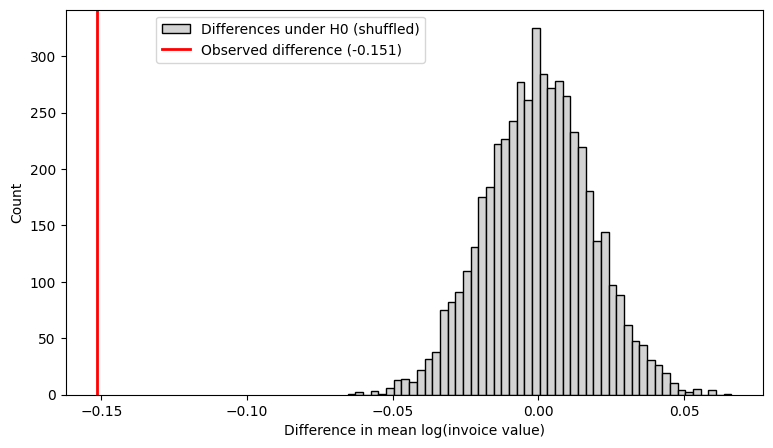

In [332]:
inv["Period"] = np.where(inv["Hour"] < 12, "Morning", "Afternoon")

print(inv.groupby("Period")["InvoiceValue"].agg(["count", "median", "mean"]).round(1))

A = inv.loc[inv["Period"] == "Morning", "LogValue"].to_numpy()
B = inv.loc[inv["Period"] == "Afternoon", "LogValue"].to_numpy()
observed = B.mean() - A.mean()

rng = np.random.default_rng(42)
pooled = np.concatenate([A, B])
n_perm = 5000
null_diffs = np.empty(n_perm)
for i in range(n_perm):
    shuffled = rng.permutation(pooled)
    null_diffs[i] = shuffled[:len(B)].mean() - shuffled[len(B):].mean()

# p-value (با +1 تا هرگز دقیقاً صفر گزارش نشود)
p_perm = (np.sum(np.abs(null_diffs) >= abs(observed)) + 1) / (n_perm + 1)

print(f"\nتفاوت مشاهده‌شده (log): {observed:.3f}   → نسبت: {np.exp(observed):.3f}")
print(f"بیشترین تفاوت در بین {n_perm} جایگشت: {np.abs(null_diffs).max():.3f}")
print(f"p-value (شبیه‌سازی): {p_perm:.4f}")

# تأیید با t-test
t_ab = ttest_ind(B, A, equal_var=False)
print(f"تأیید با t-test:      t = {t_ab.statistic:.2f}   p = {t_ab.pvalue:.3g}")

results.append({"test": "A/B permutation: afternoon vs morning (log value)", "statistic": observed,
                "p-value": p_perm, "effect size": f"ratio = {np.exp(observed):.2f}"})

plt.figure(figsize=(9, 5))
plt.hist(null_diffs, bins=50, color="lightgray", edgecolor="black", label="Differences under H0 (shuffled)")
plt.axvline(observed, color="red", lw=2, label=f"Observed difference ({observed:.3f})")
plt.xlabel("Difference in mean log(invoice value)")
plt.ylabel("Count")
plt.legend(loc="upper left", bbox_to_anchor=(0.12, 1.0))
plt.show()

<div dir="rtl">

**تفسیر:**

- در هیچ‌کدام از ۵۰۰۰ جابه‌جایی تصادفی تفاوتی به بزرگی تفاوت واقعی دیده نشد: بزرگ‌ترین تفاوت تصادفی حدود 0.066 بود و تفاوت واقعی 0.151 است (خط قرمز بسیار دورتر از توده‌ی هیستوگرام است). پس **p < 0.001** و **H₀ رد می‌شود**.
- **جهت:** فاکتورهای **بعدازظهر کوچک‌ترند**. نسبت میانگین‌های هندسی حدود **0.86** است؛ یعنی فاکتور معمولی بعدازظهر حدود 14٪ کوچک‌تر از فاکتور معمولی قبل از ظهر است (میانه‌ها: 293 در برابر 311 پوند).
- **تأیید:** t-test هم همین نتیجه را می‌دهد.
- **اندازه‌ی اثر کوچک** است (تفاوت 14٪). این نتیجه برای تصمیم‌گیری مفید است، اما دلیل آن (مثلاً اینکه مشتریان عمده زودتر سفارش می‌دهند) را نمی‌توان از این داده نتیجه گرفت.

</div>

<div dir="rtl">

### ۹.۵ ANOVA: ارزش فاکتور در روزهای هفته

برای مقایسه‌ی **بیش از دو گروه** از ANOVA (تحلیل واریانس یک‌طرفه) استفاده می‌کنیم. ۶ روز کاری داریم (شنبه تراکنشی ندارد).

- H₀: میانگین (لگاریتم) ارزش فاکتور در همه‌ی روزها برابر است.
- H₁: دست‌کم یک روز با بقیه فرق دارد.

چند نکته:
- ANOVA را روی **لگاریتم** اجرا می‌کنیم تا به نرمال نزدیک‌تر باشد.
- ANOVA فرض می‌کند **واریانس گروه‌ها برابر** است. با **آزمون Levene** این را می‌سنجیم.
- اگر ANOVA معنادار شود فقط می‌دانیم «یک جایی تفاوت هست». برای پیدا کردن اینکه **کدام روزها** با هم فرق دارند از **آزمون تعقیبی Tukey HSD** استفاده می‌کنیم.
- اندازه‌ی اثر: **η² (اتا-مربع)**، سهمی از تغییرات که با روز هفته توضیح داده می‌شود (کمتر از 0.01 = ناچیز).

</div>

In [333]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Sunday"]
groups = [inv.loc[inv["DayOfWeek"] == d, "LogValue"].to_numpy() for d in days]

day_summary = pd.DataFrame({
    "n": [len(g) for g in groups],
    "mean_log": [g.mean() for g in groups],
    "std_log": [g.std() for g in groups],
    "geometric_mean (£)": [np.exp(g.mean()) for g in groups],
}, index=days)
print(day_summary.round(3))

anova = f_oneway(*groups)
lev = stats.levene(*groups)


grand = inv["LogValue"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = ((inv["LogValue"] - grand) ** 2).sum()
eta2 = ss_between / ss_total

print(f"\nANOVA:  F = {anova.statistic:.2f}   p = {anova.pvalue:.3g}   η² = {eta2:.4f}")
print(f"Levene (برابری واریانس‌ها):  W = {lev.statistic:.2f}   p = {lev.pvalue:.3g}")

results.append({"test": "ANOVA: log invoice value by weekday", "statistic": anova.statistic,
                "p-value": anova.pvalue, "effect size": f"eta² = {eta2:.4f}"})


tukey = stats.tukey_hsd(*groups)
pd.DataFrame(tukey.pvalue, index=days, columns=days).round(4)

              n  mean_log  std_log  geometric_mean (£)
Monday     3076     5.595    1.222             268.992
Tuesday    3508     5.622    1.238             276.573
Wednesday  3667     5.544    1.203             255.642
Thursday   4209     5.550    1.179             257.232
Friday     3108     5.492    1.328             242.657
Sunday     2203     5.478    0.960             239.399

ANOVA:  F = 6.44   p = 5.54e-06   η² = 0.0016
Levene (برابری واریانس‌ها):  W = 20.14   p = 4.22e-20


,Monday,Tuesday,Wednesday,Thursday,Friday,Sunday
Monday,1.0000,0.9376,0.5121,0.6214,0.0100,0.0069
Tuesday,0.9376,1.0000,0.0627,0.0892,0.0001,0.0002
Wednesday,0.5121,0.0627,1.0000,0.9999,0.4812,0.3291
Thursday,0.6214,0.0892,0.9999,1.0000,0.3147,0.2066
Friday,0.0100,0.0001,0.4812,0.3147,1.0000,0.9986
Sunday,0.0069,0.0002,0.3291,0.2066,0.9986,1.0000


<div dir="rtl">

**تفسیر:**

- **ANOVA:** p ≈ 5.5×10⁻⁶، پس **H₀ رد می‌شود**: میانگین ارزش فاکتور در همه‌ی روزها یکسان نیست.
- **اندازه‌ی اثر:** η² ≈ 0.0016، یعنی **کمتر از 0.2٪** از تغییرات ارزش فاکتور با روز هفته توضیح داده می‌شود. اثر **بسیار کوچک** است و از نظر کاربردی تقریباً ناچیز.
- **Tukey:** فقط چهار جفت معنادارند (p < 0.05): **دوشنبه و سه‌شنبه** با **جمعه و یکشنبه**. فاکتورهای دوشنبه و سه‌شنبه کمی بزرگ‌ترند (میانگین هندسی حدود 269 و 276 پوند در برابر حدود 243 و 239 پوند برای جمعه و یکشنبه، یعنی حدود 10 تا 15٪ اختلاف).
- **احتیاط:** آزمون Levene نشان می‌دهد واریانس گروه‌ها برابر نیست (یکشنبه پراکندگی کمتری دارد). ANOVA با گروه‌های بزرگ نسبتاً مقاوم است، اما نتیجه را باید با احتیاط خواند.

</div>

<div dir="rtl">

### ۹.۶ آزمون کای‌دو: آیا سهم مشتریان خارجی در روزهای هفته و فصل‌ها فرق دارد؟

حالا دو متغیر **دسته‌ای** داریم (روز هفته یا فصل، و گروه کشور). برای بررسی استقلال از **کای‌دو استقلال** استفاده می‌کنیم.

- H₀: دو متغیر مستقل‌اند (سهم فاکتورهای خارجی در همه‌ی روزها/فصل‌ها یکی است).
- H₁: وابسته‌اند.

**پیش‌شرط:** فراوانی مورد انتظار هر خانه باید حداقل 5 باشد. **اندازه‌ی اثر:** Cramér's V (حدود 0.1 کوچک، 0.3 متوسط).

</div>

Group      Other    UK
DayOfWeek             
Monday       302  2774
Tuesday      294  3214
Wednesday    362  3305
Thursday     426  3783
Friday       354  2754
Sunday       134  2069

درصد فاکتورهای خارجی در هر روز:
DayOfWeek
Monday        9.8
Tuesday       8.4
Wednesday     9.9
Thursday     10.1
Friday       11.4
Sunday        6.1

کمینه‌ی فراوانی مورد انتظار: 208.6   (باید ≥ 5 باشد)
روز هفته:  χ² = 50.92   df = 5   p = 8.99e-10   Cramér V = 0.051

فصل:      χ² = 6.19   df = 3   p = 0.103   Cramér V = 0.018


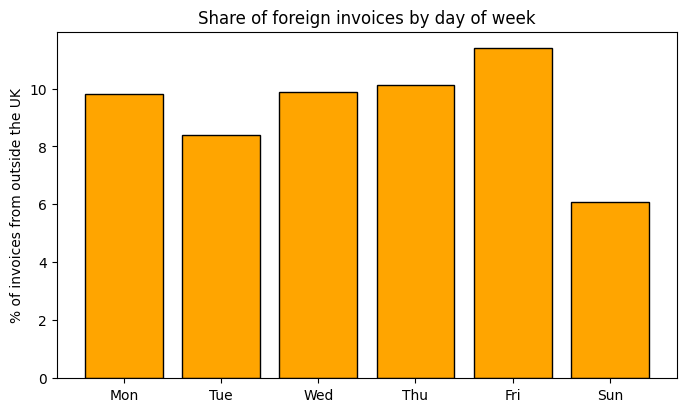

In [334]:
# ---- روز هفته × گروه کشور
table_day = pd.crosstab(inv["DayOfWeek"], inv["Group"]).reindex(days)
chi2, p_day, dof, expected = chi2_contingency(table_day)
v_day = np.sqrt(chi2 / (table_day.to_numpy().sum() * (min(table_day.shape) - 1)))
share_other = table_day["Other"] / table_day.sum(axis=1) * 100

print(table_day)
print("\nدرصد فاکتورهای خارجی در هر روز:")
print(share_other.round(1).to_string())
print(f"\nکمینه‌ی فراوانی مورد انتظار: {expected.min():.1f}   (باید ≥ 5 باشد)")
print(f"روز هفته:  χ² = {chi2:.2f}   df = {dof}   p = {p_day:.3g}   Cramér V = {v_day:.3f}")

results.append({"test": "Chi-square: weekday x (UK / other)", "statistic": chi2,
                "p-value": p_day, "effect size": f"V = {v_day:.3f}"})

full = inv[inv["InvoiceDate"] < "2011-12-01"].copy()
full["Quarter"] = full["InvoiceDate"].dt.quarter
table_q = pd.crosstab(full["Quarter"], full["Group"])
chi2_q, p_q, dof_q, expected_q = chi2_contingency(table_q)
v_q = np.sqrt(chi2_q / (table_q.to_numpy().sum() * (min(table_q.shape) - 1)))
print(f"\nفصل:      χ² = {chi2_q:.2f}   df = {dof_q}   p = {p_q:.3g}   Cramér V = {v_q:.3f}")

results.append({"test": "Chi-square: quarter x (UK / other)", "statistic": chi2_q,
                "p-value": p_q, "effect size": f"V = {v_q:.3f}"})

plt.figure(figsize=(8, 4.5))
plt.bar([d[:3] for d in days], share_other.values, color="orange", edgecolor="black")
plt.ylabel("% of invoices from outside the UK")
plt.title("Share of foreign invoices by day of week")
plt.show()

<div dir="rtl">

**تفسیر:**

- **روز هفته:** p ≈ 9×10⁻¹⁰، پس **H₀ رد می‌شود**. سهم فاکتورهای خارجی از **6.1٪ در یکشنبه** تا **11.4٪ در جمعه** تغییر می‌کند. Cramér's V ≈ 0.05 یعنی اثر **خیلی کوچک** است.
- **فصل:** p ≈ 0.103 که از 0.05 بزرگ‌تر است، پس **H₀ رد نمی‌شود**. سهم مشتریان خارجی در فصل‌های مختلف تقریباً ثابت است (بین 8.6٪ و 10.1٪). این یعنی افزایش فروش در پاییز هم‌زمان در هر دو گروه رخ می‌دهد و ترکیب مشتریان عوض نمی‌شود.
- «رد نکردن H₀» یعنی **شواهد کافی علیه آن نداریم**؛ ثابت نمی‌کند که دو چیز دقیقاً برابرند.

</div>

<div dir="rtl">

### ۹.۷ جدول خلاصه‌ی آزمون‌ها

</div>

In [335]:
summary = pd.DataFrame(results)
summary["decision (α=0.05)"] = np.where(summary["p-value"] < alpha, "reject H0", "fail to reject H0")
summary["p-value"] = summary["p-value"].map(lambda v: "< 1e-300" if v < 1e-300 else f"{v:.3g}")
summary["statistic"] = summary["statistic"].map("{:,.3f}".format)
summary.set_index("test")

,statistic,p-value,effect size,decision (α=0.05)
test,,,,
Jarque-Bera: log(UnitPrice) normal?,198.236,8.99e-44,"skew=-0.05, kurt=-0.02",reject H0
KS: gaps between invoices exponential?,0.108,1.84e-130,D = 0.108,reject H0
Welch t-test: Other vs UK (log invoice value),16.224,3.8e-56,d = 0.38,reject H0
Mann-Whitney U: Other vs UK (invoice value),"20,455,568.500",6.24e-56,P(Other>UK) = 0.61,reject H0
A/B permutation: afternoon vs morning (log value),-0.151,0.0002,ratio = 0.86,reject H0
ANOVA: log invoice value by weekday,6.435,5.54e-06,eta² = 0.0016,reject H0
Chi-square: weekday x (UK / other),50.917,8.99e-10,V = 0.051,reject H0
Chi-square: quarter x (UK / other),6.190,0.103,V = 0.018,fail to reject H0


<div dir="rtl">

## ۱۰. نتیجه‌گیری کلی

### داده و پاک‌سازی
از **541,909** ردیف خام، پس از حذف ردیف‌های تکراری، فاکتورهای لغو‌شده (و سه فاکتور «A»)، قیمت و تعداد نامعتبر، کدهای غیرکالا و دو سفارش پرت، **522,502** ردیف معتبر (حدود 19,771 فاکتور) ماند. ردیف‌های بدون شناسه‌ی مشتری (حدود 25٪) نگه داشته شدند، چون بیشتر تحلیل‌ها به مشتری نیاز نداشتند.

### یافته‌های تحلیل اکتشافی
- **فروش کل حدود 10 میلیون پوند** در 19,771 فاکتور بود (حدود 4,333 مشتری شناخته‌شده). میانگین ارزش فاکتور حدود 506 و میانه حدود 302 پوند است؛ این فاصله از چولگی شدید به راست می‌آید.
- **بریتانیا حدود 85٪** فروش را دارد. هلند، ایرلند، آلمان، فرانسه و استرالیا بزرگ‌ترین بازارهای خارجی‌اند.
- **فروش فصلی است:** از سپتامبر شروع به رشد می‌کند و نوامبر 2011 با حدود 1.45 میلیون پوند اوج می‌گیرد. دسامبر 2011 ناقص است (داده تا 9 دسامبر) و افت آن واقعی نیست.
- **الگوی زمانی:** بیشترین فاکتور بین ساعت 10 تا 15 و اوج آن ساعت 12 است. پنج‌شنبه شلوغ‌ترین و یکشنبه خلوت‌ترین روز است و **در شنبه هیچ تراکنشی ثبت نشده**.
- **محصولات:** پردرآمدترین محصول `REGENCY CAKESTAND 3 TIER` است، ولی پرفروش‌ترین از نظر تعداد محصول دیگری است. «پرفروش» باید دقیق تعریف شود.

### توزیع‌ها
- **قیمت واحد لگ‌نرمال است**: لگاریتمش چولگی و کشیدگی تقریباً صفر دارد (‎−0.05 و ‎−0.02).
- **فاصله‌ی زمانی بین فاکتورها تقریباً نمایی است** (چندک‌های مشاهده‌شده و نظری بسیار نزدیک‌اند)، ولی از نمایی پراکنده‌تر است (انحراف معیار 7.8 در برابر میانگین 6.7 دقیقه).
- **تعداد فاکتور در ساعت 12 در بازه‌ی نرخ ثابت (مارس تا اوت) تقریباً پواسون است** (میانگین 9.68 و واریانس 10.75).

### نتایج آزمون‌های آماری

| فرضیه | آزمون | نتیجه (α = 0.05) | اندازه‌ی اثر |
|-------|--------|-------------------|--------------|
| log قیمت نرمال است | جارک-برا، KS | رد می‌شود (به‌خاطر n بسیار بزرگ) | چولگی و کشیدگی ≈ 0 |
| ارزش فاکتور UK و خارجی یکی است | t-test ولچ، Mann-Whitney | **رد می‌شود**؛ فاکتور خارجی بزرگ‌تر | d = 0.38؛ احتمال 61٪ |
| ارزش فاکتور قبل و بعد از ظهر یکی است | A/B (جایگشت) | **رد می‌شود**؛ بعدازظهر حدود 14٪ کوچک‌تر | کوچک |
| ارزش فاکتور در روزهای هفته یکی است | ANOVA + Tukey | **رد می‌شود**؛ دوشنبه/سه‌شنبه بزرگ‌تر از جمعه/یکشنبه | η² = 0.0016 (ناچیز) |
| سهم فاکتور خارجی در روزهای هفته یکی است | کای‌دو | **رد می‌شود** (6٪ یکشنبه تا 11٪ جمعه) | V = 0.05 (خیلی کوچک) |
| سهم فاکتور خارجی در فصل‌ها یکی است | کای‌دو | **رد نمی‌شود** (p = 0.10) | V = 0.02 (عملاً صفر) |

### جمع‌بندی
1. **قوی‌ترین نتیجه:** مشتریان خارجی فاکتورهای بزرگ‌تری دارند (حدود 1.6 برابر در حالت معمول). هر سه روش (t-test، Mann-Whitney و جایگشت) روی جهت توافق دارند و اندازه‌ی اثر کوچک تا متوسط است.
2. **اثرهای زمانی (ساعت و روز هفته) معنادارند ولی کوچک‌اند.** با نمونه‌ی بزرگ این دو آزمون حتی تفاوت‌های ناچیز را هم پیدا می‌کنند، پس فقط «معنادار بودن» کافی نیست؛ اندازه‌ی اثر (0.2٪ تا 14٪) نشان می‌دهد این تفاوت‌ها برای تصمیم‌گیری تجاری اهمیت محدودی دارند.
3. **الگوی فصلی فروش** (اوج پاییز) در هر دو گروه مشتریان یکسان است: سهم مشتریان خارجی در فصل‌ها فرق معناداری ندارد.
4. **انتخاب آزمون مهم است:** چون داده‌ها چوله‌اند، آزمون‌های ناپارامتری و شبیه‌سازی را کنار آزمون‌های پارامتری به کار بردیم و نتیجه‌ها هم‌خوان بودند.

> این یافته‌ها فقط **تفاوت و همبستگی** را نشان می‌دهند، نه علت. مثلاً علت بزرگ‌تر بودن فاکتورهای خارجی (مثلاً عمده‌خرید) با این داده آزمون نشده است.

## ۱۱. محدودیت‌ها
- داده فقط **یک سال و یک فروشگاه** است؛ تعمیم به کل بازار درست نیست.
- حدود **25٪ فروش بدون شناسه‌ی مشتری** بود؛ تحلیل مشتری فقط درباره‌ی بقیه است.
- **فاکتورهای لغو‌شده را حذف کردیم**؛ در تحلیل دقیق‌تر درآمد خالص باید برگشتی‌ها لحاظ شود.
- آزمون‌ها فرض می‌کنند فاکتورها **از هم مستقل‌اند**، ولی چند فاکتور می‌توانند مال یک مشتری باشند. این می‌تواند p-value‌ها را کمی خوش‌بینانه کند.
- زمان‌ها تا **دقیقه** ثبت شده‌اند و **دسامبر 2011 ناقص** است.

</div>